<a href="https://colab.research.google.com/github/parinitha672/Social-Media-Sentiment-Analysis-and-Virality-Prediction/blob/main/SOCIAL_MEDIA_SENTIMENT_ANALYSIS_AND_VIRALITY_PREDICTION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data-Driven Social Engagement Initiative

### Major Project – Data Science

This project analyzes social media content performance and audience comments
to understand engagement, virality, sentiment, relatability, and content strategy.

Datasets:
1. Instagram Analytics Dataset
2. YouTube Comments Dataset

In [11]:
import pandas as pd
import numpy as np

In [12]:
instagram_df = pd.read_csv("/content/Instagram_Analytics.csv")
print("Instagram dataset loaded successfully!")
print("Shape:", instagram_df.shape)

Instagram dataset loaded successfully!
Shape: (29999, 23)


In [13]:
youtube_df = pd.read_csv('/content/YouTube Comments Dataset with Sentiment Toxicity and Spam Labels (45K Rows).csv')
print("YouTube dataset loaded successfully!")
print("Shape:", youtube_df.shape)

YouTube dataset loaded successfully!
Shape: (45005, 14)


In [14]:
instagram_df.head()

,post_id,account_id,account_type,follower_count,media_type,content_category,traffic_source,has_call_to_action,post_datetime,post_date,...,comments,shares,saves,reach,impressions,engagement_rate,followers_gained,caption_length,hashtags_count,performance_bucket_label
0,IG0000001,7,brand,3551,reel,Technology,Home Feed,1,2024-11-30 06:00:00,2024-11-30,...,5,7,34,4327,6230,0.0385,899,100,7,medium
1,IG0000002,20,creator,31095,image,Fitness,Hashtags,1,2025-08-15 15:00:00,2025-08-15,...,10,21,68,7451,8268,0.0663,805,122,5,viral
2,IG0000003,15,brand,8167,reel,Beauty,Reels Feed,0,2025-09-11 16:00:00,2025-09-11,...,2,1,22,1639,2616,0.0531,758,115,8,high
3,IG0000004,11,creator,9044,carousel,Music,External,0,2025-09-18 03:00:00,2025-09-18,...,0,7,0,2877,3171,0.0309,402,115,7,medium
4,IG0000005,8,creator,15986,reel,Technology,Profile,0,2025-03-21 09:00:00,2025-03-21,...,8,5,21,5350,8503,0.0221,155,112,9,low


In [15]:
youtube_df.head()

,channel_username,channel_id,video_id,video_title,comment_text,comment_id,author,published_at,like_count,reply_count,language,label_sentiment,label_toxicity,label_spam
0,@WWE,UCJ5v_MCY6GNUBTO8-D3XoAg,wj56SBaroCE,Jade Cargill continues to perform knowing the ...,Jade was pushed fast in another company. WWE i...,UgzBqHwpN5Vh2yrBzgx4AaABAg,@IFLDook,2025-06-24T19:52:54Z,2,0,en,positive,toxic,not spam
1,@ZeeTV,UCppHT7SZKKvar4Oc9J4oljQ,3KWNKzs_ptQ,Tum Se Tum Tak - तुम से तुम तक - 7th July Onwa...,Are ye 20 sal mushki se jiye ga tab ladki bewa...,UgwG3UA7RYn2WQG4UqR4AaABAg,@KaynatYasmin-r4l,2025-06-25T18:19:01Z,2,0,so,neutral,toxic,not spam
2,@ColorsTV,UC55IWqFLDH1Xp7iu1_xknRA,eqwlbP4f4G4,Laughter Chefs S2 | Full Episode - 41 | India ...,Aly is fcking rude for no reason its laughter ...,UgylheWfFiDbrcu_GCB4AaABAg,@Geejayy616,2025-06-24T20:18:53Z,0,0,en,neutral,toxic,not spam
3,@김프로KIMPRO,UCiVs2pnGW5mLIc1jS2nxhjg,R_gAdQqH6gA,Perfect Featuring | First Take🎬🤣,Aaaaaaaaaaaaaaaaaaaaaaaaaaaaaa,UgwFwHS549OChJ8Undd4AaABAg,@FranciscoJavierBritogarcia,2025-06-26T05:34:30Z,0,0,so,neutral,toxic,not spam
4,@ColorsTV,UC55IWqFLDH1Xp7iu1_xknRA,g2pWwrK2fyE,Meri Bhavya Life | Ep. 55 | Uma Requests Risha...,bhavya is furfect maching rishank you don't mi...,UgyzIzjTUfhJAqx-CEh4AaABAg,@ChocoHashi,2025-06-25T04:37:32Z,0,0,en,negative,toxic,not spam


In [16]:
print("Instagram Columns:")
print(instagram_df.columns.tolist())

Instagram Columns:
['post_id', 'account_id', 'account_type', 'follower_count', 'media_type', 'content_category', 'traffic_source', 'has_call_to_action', 'post_datetime', 'post_date', 'post_hour', 'day_of_week', 'likes', 'comments', 'shares', 'saves', 'reach', 'impressions', 'engagement_rate', 'followers_gained', 'caption_length', 'hashtags_count', 'performance_bucket_label']


In [17]:
print("YouTube Columns:")
print(youtube_df.columns.tolist())

YouTube Columns:
['channel_username', 'channel_id', 'video_id', 'video_title', 'comment_text', 'comment_id', 'author', 'published_at', 'like_count', 'reply_count', 'language', 'label_sentiment', 'label_toxicity', 'label_spam']


In [18]:
instagram_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29999 entries, 0 to 29998
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   post_id                   29999 non-null  object 
 1   account_id                29999 non-null  int64  
 2   account_type              29999 non-null  object 
 3   follower_count            29999 non-null  int64  
 4   media_type                29999 non-null  object 
 5   content_category          29999 non-null  object 
 6   traffic_source            29999 non-null  object 
 7   has_call_to_action        29999 non-null  int64  
 8   post_datetime             29999 non-null  object 
 9   post_date                 29999 non-null  object 
 10  post_hour                 29999 non-null  int64  
 11  day_of_week               29999 non-null  object 
 12  likes                     29999 non-null  int64  
 13  comments                  29999 non-null  int64  
 14  shares

In [19]:
youtube_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45005 entries, 0 to 45004
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   channel_username  45005 non-null  object
 1   channel_id        45005 non-null  object
 2   video_id          45005 non-null  object
 3   video_title       44954 non-null  object
 4   comment_text      45000 non-null  object
 5   comment_id        45005 non-null  object
 6   author            44997 non-null  object
 7   published_at      45005 non-null  object
 8   like_count        45005 non-null  int64 
 9   reply_count       45005 non-null  int64 
 10  language          40034 non-null  object
 11  label_sentiment   45005 non-null  object
 12  label_toxicity    45005 non-null  object
 13  label_spam        45005 non-null  object
dtypes: int64(2), object(12)
memory usage: 4.8+ MB


In [20]:
instagram_df.isnull().sum()

,0
post_id,0
account_id,0
account_type,0
follower_count,0
media_type,0
content_category,0
traffic_source,0
has_call_to_action,0
post_datetime,0
post_date,0


In [21]:
youtube_df.isnull().sum()

,0
channel_username,0
channel_id,0
video_id,0
video_title,51
comment_text,5
comment_id,0
author,8
published_at,0
like_count,0
reply_count,0


In [22]:
print("Instagram duplicate rows:", instagram_df.duplicated().sum())

Instagram duplicate rows: 0


In [23]:
print("YouTube duplicate rows:", youtube_df.duplicated().sum())

YouTube duplicate rows: 222


In [24]:
instagram_df.describe()

,account_id,follower_count,has_call_to_action,post_hour,likes,comments,shares,saves,reach,impressions,engagement_rate,followers_gained,caption_length,hashtags_count
count,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000
mean,10.567819,10278.305477,0.348778,11.499417,287.653588,8.521917,14.426614,42.517284,6272.475449,8466.952498,0.042107,502.152805,120.081169,7.987933
std,5.763952,6691.862669,0.476592,6.900587,317.647682,10.116505,16.420899,47.808844,4985.877059,6825.900355,0.024095,290.364038,11.009108,2.828130
min,1.000000,3083.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,268.000000,327.000000,0.000000,0.000000,70.000000,0.000000
25%,6.000000,5824.000000,0.000000,6.000000,104.000000,3.000000,5.000000,15.000000,3058.000000,4102.000000,0.024000,251.000000,113.000000,6.000000
50%,11.000000,9044.000000,0.000000,12.000000,199.000000,6.000000,10.000000,29.000000,4913.000000,6595.000000,0.040600,501.000000,120.000000,8.000000
75%,16.000000,10739.000000,1.000000,17.000000,363.000000,11.000000,19.000000,54.000000,7863.000000,10620.500000,0.057000,755.000000,127.000000,10.000000
max,20.000000,31095.000000,1.000000,23.000000,10632.000000,339.000000,516.000000,1542.000000,73339.000000,105203.000000,0.271000,1000.000000,166.000000,21.000000


In [25]:
youtube_df.describe()

,like_count,reply_count
count,45005.000000,45005.000000
mean,67.192934,1.974936
std,2123.489221,32.379362
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,1.000000,0.000000
max,218989.000000,1000.000000


In [26]:
print("Account Types:")
print(instagram_df['account_type'].value_counts())
print("\nMedia Types:")
print(instagram_df['media_type'].value_counts())
print("\nContent Categories:")
print(instagram_df['content_category'].value_counts())
print("\nTraffic Sources:")
print(instagram_df['traffic_source'].value_counts())

Account Types:
account_type
creator    20944
brand       9055
Name: count, dtype: int64

Media Types:
media_type
image       11927
carousel    10627
reel         7445
Name: count, dtype: int64

Content Categories:
content_category
Photography    3035
Fashion        3034
Technology     3025
Lifestyle      3017
Food           3010
Fitness        3004
Music          3003
Travel         2968
Beauty         2953
Comedy         2950
Name: count, dtype: int64

Traffic Sources:
traffic_source
Home Feed     5069
Hashtags      5063
Reels Feed    5026
External      5005
Profile       4962
Explore       4874
Name: count, dtype: int64


In [27]:
print("Performance Buckets:")
print(instagram_df['performance_bucket_label'].value_counts())

Performance Buckets:
performance_bucket_label
viral     7500
high      7500
low       7500
medium    7499
Name: count, dtype: int64


In [28]:
print("Sentiment Distribution:")
print(youtube_df['label_sentiment'].value_counts())

Sentiment Distribution:
label_sentiment
neutral     22985
positive    18210
negative     3810
Name: count, dtype: int64


In [29]:
print("Toxicity Distribution:")
print(youtube_df['label_toxicity'].value_counts())

Toxicity Distribution:
label_toxicity
non-toxic    43105
toxic         1900
Name: count, dtype: int64


In [30]:
print("Spam Distribution:")
print(youtube_df['label_spam'].value_counts())

Spam Distribution:
label_spam
not spam    44189
spam          816
Name: count, dtype: int64


In [31]:
print("Top Languages:")
print(youtube_df['language'].value_counts().head(15))

Top Languages:
language
en    15100
id     4063
so     2158
bn     2067
ml     1589
tl     1431
sw     1291
kn     1101
hi     1068
et     1051
mr      671
de      562
ro      560
ta      536
af      452
Name: count, dtype: int64


In [32]:
print("Instagram date range:")
print("Start:", instagram_df['post_datetime'].min())
print("End:", instagram_df['post_datetime'].max())

Instagram date range:
Start: 2024-11-19 00:00:00
End: 2025-11-19 23:00:00


In [33]:
print("YouTube comment date range:")
print("Start:", youtube_df['published_at'].min())
print("End:", youtube_df['published_at'].max())

YouTube comment date range:
Start: 2013-06-19T15:29:12Z
End: 2025-06-26T11:12:06Z


In [34]:
instagram_clean = instagram_df.copy()
youtube_clean = youtube_df.copy()
print("Working copies created successfully.")

Working copies created successfully.


In [35]:
instagram_before = len(instagram_clean)
instagram_clean = instagram_clean.drop_duplicates().reset_index(drop=True)
instagram_after = len(instagram_clean)
print("Instagram rows before:", instagram_before)
print("Instagram rows after:", instagram_after)
print("Duplicates removed:", instagram_before - instagram_after)

Instagram rows before: 29999
Instagram rows after: 29999
Duplicates removed: 0


In [36]:
youtube_before = len(youtube_clean)
youtube_clean = youtube_clean.drop_duplicates().reset_index(drop=True)
youtube_after = len(youtube_clean)
print("YouTube rows before:", youtube_before)
print("YouTube rows after:", youtube_after)
print("Duplicates removed:", youtube_before - youtube_after)

YouTube rows before: 45005
YouTube rows after: 44783
Duplicates removed: 222


In [37]:
instagram_clean.columns = instagram_clean.columns.str.strip()
print(instagram_clean.columns.tolist())

['post_id', 'account_id', 'account_type', 'follower_count', 'media_type', 'content_category', 'traffic_source', 'has_call_to_action', 'post_datetime', 'post_date', 'post_hour', 'day_of_week', 'likes', 'comments', 'shares', 'saves', 'reach', 'impressions', 'engagement_rate', 'followers_gained', 'caption_length', 'hashtags_count', 'performance_bucket_label']


In [38]:
youtube_clean.columns = youtube_clean.columns.str.strip()
print(youtube_clean.columns.tolist())

['channel_username', 'channel_id', 'video_id', 'video_title', 'comment_text', 'comment_id', 'author', 'published_at', 'like_count', 'reply_count', 'language', 'label_sentiment', 'label_toxicity', 'label_spam']


In [39]:
instagram_text_columns = instagram_clean.select_dtypes(include='object').columns
for column in instagram_text_columns:instagram_clean[column] = instagram_clean[column].str.strip()
print("Instagram text columns cleaned.")

Instagram text columns cleaned.


In [40]:
youtube_text_columns = youtube_clean.select_dtypes(include='object').columns
for column in youtube_text_columns:youtube_clean[column] = youtube_clean[column].str.strip()
print("YouTube text columns cleaned.")

YouTube text columns cleaned.


In [41]:
instagram_clean['post_datetime'] = pd.to_datetime(
    instagram_clean['post_datetime'],
    errors='coerce'
)
instagram_clean['post_date'] = pd.to_datetime(
    instagram_clean['post_date'],
    errors='coerce'
)
print(instagram_clean[['post_datetime', 'post_date']].dtypes)

post_datetime    datetime64[ns]
post_date        datetime64[ns]
dtype: object


In [42]:
youtube_clean['published_at'] = pd.to_datetime(
    youtube_clean['published_at'],
    errors='coerce'
)
print(youtube_clean['published_at'].dtype)

datetime64[ns, UTC]


In [43]:
youtube_clean['video_id'] = youtube_clean['video_id'].replace('#NAME?', np.nan)
print("Remaining #NAME? values:",(youtube_clean['video_id'] == '#NAME?').sum())

Remaining #NAME? values: 0


In [44]:
instagram_clean.isnull().sum()

,0
post_id,0
account_id,0
account_type,0
follower_count,0
media_type,0
content_category,0
traffic_source,0
has_call_to_action,0
post_datetime,0
post_date,0


In [45]:
print("Missing comments:",youtube_clean['comment_text'].isnull().sum())

Missing comments: 5


In [46]:
youtube_clean = youtube_clean.dropna(
    subset=['comment_text']
).reset_index(drop=True)
print("YouTube rows after removing missing comments:",len(youtube_clean))

YouTube rows after removing missing comments: 44778


In [47]:
youtube_clean['comment_text_clean'] = (
    youtube_clean['comment_text']
    .astype(str)
    .str.strip()
    .str.lower()
)
print(youtube_clean[['comment_text', 'comment_text_clean']].head())

                                        comment_text  \
0  Jade was pushed fast in another company. WWE i...   
1  Are ye 20 sal mushki se jiye ga tab ladki bewa...   
2  Aly is fcking rude for no reason its laughter ...   
3                     Aaaaaaaaaaaaaaaaaaaaaaaaaaaaaa   
4  bhavya is furfect maching rishank you don't mi...   

                                  comment_text_clean  
0  jade was pushed fast in another company. wwe i...  
1  are ye 20 sal mushki se jiye ga tab ladki bewa...  
2  aly is fcking rude for no reason its laughter ...  
3                     aaaaaaaaaaaaaaaaaaaaaaaaaaaaaa  
4  bhavya is furfect maching rishank you don't mi...  


In [48]:
youtube_clean['video_title'] = youtube_clean['video_title'].fillna('Unknown Video Title')
print("Missing video titles:",youtube_clean['video_title'].isnull().sum())

Missing video titles: 0


In [49]:
youtube_clean['author'] = youtube_clean['author'].fillna('Unknown Author')
print("Missing authors:",youtube_clean['author'].isnull().sum())

Missing authors: 0


In [50]:
youtube_clean['language'] = youtube_clean['language'].fillna('Unknown')
print("Missing languages:", youtube_clean['language'].isnull().sum())

Missing languages: 0


In [51]:
instagram_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29999 entries, 0 to 29998
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   post_id                   29999 non-null  object        
 1   account_id                29999 non-null  int64         
 2   account_type              29999 non-null  object        
 3   follower_count            29999 non-null  int64         
 4   media_type                29999 non-null  object        
 5   content_category          29999 non-null  object        
 6   traffic_source            29999 non-null  object        
 7   has_call_to_action        29999 non-null  int64         
 8   post_datetime             29999 non-null  datetime64[ns]
 9   post_date                 29999 non-null  datetime64[ns]
 10  post_hour                 29999 non-null  int64         
 11  day_of_week               29999 non-null  object        
 12  likes             

In [52]:
youtube_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44778 entries, 0 to 44777
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype              
---  ------              --------------  -----              
 0   channel_username    44778 non-null  object             
 1   channel_id          44778 non-null  object             
 2   video_id            43996 non-null  object             
 3   video_title         44778 non-null  object             
 4   comment_text        44778 non-null  object             
 5   comment_id          44778 non-null  object             
 6   author              44778 non-null  object             
 7   published_at        44778 non-null  datetime64[ns, UTC]
 8   like_count          44778 non-null  int64              
 9   reply_count         44778 non-null  int64              
 10  language            44778 non-null  object             
 11  label_sentiment     44778 non-null  object             
 12  label_toxicity      44778 non-nu

In [53]:
print("Instagram missing values:")
print(instagram_clean.isnull().sum())

Instagram missing values:
post_id                     0
account_id                  0
account_type                0
follower_count              0
media_type                  0
content_category            0
traffic_source              0
has_call_to_action          0
post_datetime               0
post_date                   0
post_hour                   0
day_of_week                 0
likes                       0
comments                    0
shares                      0
saves                       0
reach                       0
impressions                 0
engagement_rate             0
followers_gained            0
caption_length              0
hashtags_count              0
performance_bucket_label    0
dtype: int64


In [54]:
print("YouTube missing values:")
print(youtube_clean.isnull().sum())

YouTube missing values:
channel_username        0
channel_id              0
video_id              782
video_title             0
comment_text            0
comment_id              0
author                  0
published_at            0
like_count              0
reply_count             0
language                0
label_sentiment         0
label_toxicity          0
label_spam              0
comment_text_clean      0
dtype: int64


In [55]:
print("Instagram cleaned shape:", instagram_clean.shape)
print("YouTube cleaned shape:", youtube_clean.shape)

Instagram cleaned shape: (29999, 23)
YouTube cleaned shape: (44778, 15)


In [56]:
instagram_clean.head()

,post_id,account_id,account_type,follower_count,media_type,content_category,traffic_source,has_call_to_action,post_datetime,post_date,...,comments,shares,saves,reach,impressions,engagement_rate,followers_gained,caption_length,hashtags_count,performance_bucket_label
0,IG0000001,7,brand,3551,reel,Technology,Home Feed,1,2024-11-30 06:00:00,2024-11-30,...,5,7,34,4327,6230,0.0385,899,100,7,medium
1,IG0000002,20,creator,31095,image,Fitness,Hashtags,1,2025-08-15 15:00:00,2025-08-15,...,10,21,68,7451,8268,0.0663,805,122,5,viral
2,IG0000003,15,brand,8167,reel,Beauty,Reels Feed,0,2025-09-11 16:00:00,2025-09-11,...,2,1,22,1639,2616,0.0531,758,115,8,high
3,IG0000004,11,creator,9044,carousel,Music,External,0,2025-09-18 03:00:00,2025-09-18,...,0,7,0,2877,3171,0.0309,402,115,7,medium
4,IG0000005,8,creator,15986,reel,Technology,Profile,0,2025-03-21 09:00:00,2025-03-21,...,8,5,21,5350,8503,0.0221,155,112,9,low


In [57]:
youtube_clean.head()

,channel_username,channel_id,video_id,video_title,comment_text,comment_id,author,published_at,like_count,reply_count,language,label_sentiment,label_toxicity,label_spam,comment_text_clean
0,@WWE,UCJ5v_MCY6GNUBTO8-D3XoAg,wj56SBaroCE,Jade Cargill continues to perform knowing the ...,Jade was pushed fast in another company. WWE i...,UgzBqHwpN5Vh2yrBzgx4AaABAg,@IFLDook,2025-06-24 19:52:54+00:00,2,0,en,positive,toxic,not spam,jade was pushed fast in another company. wwe i...
1,@ZeeTV,UCppHT7SZKKvar4Oc9J4oljQ,3KWNKzs_ptQ,Tum Se Tum Tak - तुम से तुम तक - 7th July Onwa...,Are ye 20 sal mushki se jiye ga tab ladki bewa...,UgwG3UA7RYn2WQG4UqR4AaABAg,@KaynatYasmin-r4l,2025-06-25 18:19:01+00:00,2,0,so,neutral,toxic,not spam,are ye 20 sal mushki se jiye ga tab ladki bewa...
2,@ColorsTV,UC55IWqFLDH1Xp7iu1_xknRA,eqwlbP4f4G4,Laughter Chefs S2 | Full Episode - 41 | India ...,Aly is fcking rude for no reason its laughter ...,UgylheWfFiDbrcu_GCB4AaABAg,@Geejayy616,2025-06-24 20:18:53+00:00,0,0,en,neutral,toxic,not spam,aly is fcking rude for no reason its laughter ...
3,@김프로KIMPRO,UCiVs2pnGW5mLIc1jS2nxhjg,R_gAdQqH6gA,Perfect Featuring | First Take🎬🤣,Aaaaaaaaaaaaaaaaaaaaaaaaaaaaaa,UgwFwHS549OChJ8Undd4AaABAg,@FranciscoJavierBritogarcia,2025-06-26 05:34:30+00:00,0,0,so,neutral,toxic,not spam,aaaaaaaaaaaaaaaaaaaaaaaaaaaaaa
4,@ColorsTV,UC55IWqFLDH1Xp7iu1_xknRA,g2pWwrK2fyE,Meri Bhavya Life | Ep. 55 | Uma Requests Risha...,bhavya is furfect maching rishank you don't mi...,UgyzIzjTUfhJAqx-CEh4AaABAg,@ChocoHashi,2025-06-25 04:37:32+00:00,0,0,en,negative,toxic,not spam,bhavya is furfect maching rishank you don't mi...


In [58]:
instagram_clean.to_csv('/content/instagram_cleaned.csv',index=False)
youtube_clean.to_csv('/content/youtube_comments_cleaned.csv',index=False)
print("Cleaned datasets saved successfully.")

Cleaned datasets saved successfully.


In [59]:
print("===== FINAL DATA VALIDATION =====")
print("\nInstagram:")
print("Rows:", instagram_clean.shape[0])
print("Columns:", instagram_clean.shape[1])
print("Duplicate rows:", instagram_clean.duplicated().sum())
print("\nYouTube:")
print("Rows:", youtube_clean.shape[0])
print("Columns:", youtube_clean.shape[1])
print("Duplicate rows:", youtube_clean.duplicated().sum())

===== FINAL DATA VALIDATION =====

Instagram:
Rows: 29999
Columns: 23
Duplicate rows: 0

YouTube:
Rows: 44778
Columns: 15
Duplicate rows: 0


In [60]:
instagram_clean['total_interactions'] = (
    instagram_clean['likes']
    + instagram_clean['comments']
    + instagram_clean['shares']
    + instagram_clean['saves']
)
instagram_clean[['likes', 'comments', 'shares', 'saves', 'total_interactions']].head()

,likes,comments,shares,saves,total_interactions
0,194,5,7,34,240
1,449,10,21,68,548
2,114,2,1,22,139
3,91,0,7,0,98
4,154,8,5,21,188


In [61]:
instagram_clean['interaction_rate'] = (
    instagram_clean['total_interactions']
    / instagram_clean['reach'].replace(0, np.nan)
) * 100
instagram_clean[['reach', 'total_interactions', 'interaction_rate']].head()

,reach,total_interactions,interaction_rate
0,4327,240,5.546568
1,7451,548,7.354717
2,1639,139,8.480781
3,2877,98,3.406326
4,5350,188,3.514019


In [62]:
instagram_clean['save_to_share_ratio'] = (instagram_clean['saves']/instagram_clean['shares'].replace(0, np.nan))
instagram_clean[['saves', 'shares', 'save_to_share_ratio']].head()

,saves,shares,save_to_share_ratio
0,34,7,4.857143
1,68,21,3.238095
2,22,1,22.000000
3,0,7,0.000000
4,21,5,4.200000


In [63]:
instagram_clean['share_rate'] = (instagram_clean['shares'] / instagram_clean['reach'].replace(0, np.nan)) * 100
instagram_clean[['shares', 'reach', 'share_rate']].head()

,shares,reach,share_rate
0,7,4327,0.161775
1,21,7451,0.281841
2,1,1639,0.061013
3,7,2877,0.243309
4,5,5350,0.093458


In [64]:
instagram_clean['save_rate'] = (instagram_clean['saves']/ instagram_clean['reach'].replace(0, np.nan)) * 100
instagram_clean[['saves', 'reach', 'save_rate']].head()

,saves,reach,save_rate
0,34,4327,0.785764
1,68,7451,0.912629
2,22,1639,1.342282
3,0,2877,0.000000
4,21,5350,0.392523


In [65]:
instagram_clean['viral_coefficient'] = (
    (
        2 * instagram_clean['shares']
        + 2 * instagram_clean['saves']
        + instagram_clean['comments']
    )
    / instagram_clean['total_interactions'].replace(0, np.nan)
)
instagram_clean[
    ['likes', 'comments', 'shares', 'saves',
     'total_interactions', 'viral_coefficient']
].head()

,likes,comments,shares,saves,total_interactions,viral_coefficient
0,194,5,7,34,240,0.362500
1,449,10,21,68,548,0.343066
2,114,2,1,22,139,0.345324
3,91,0,7,0,98,0.142857
4,154,8,5,21,188,0.319149


In [66]:
def get_time_period(hour):
    if 5 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 21:
        return 'Evening'
    else:
        return 'Night'
instagram_clean['time_period'] = instagram_clean['post_hour'].apply(
    get_time_period
)
instagram_clean[['post_hour', 'time_period']].head()

,post_hour,time_period
0,6,Morning
1,15,Afternoon
2,16,Afternoon
3,3,Night
4,9,Morning


In [67]:
print(instagram_clean['time_period'].value_counts())

time_period
Night        9921
Morning      8763
Afternoon    6312
Evening      5003
Name: count, dtype: int64


In [68]:
instagram_clean['caption_length_group'] = pd.cut(
    instagram_clean['caption_length'],
    bins=[-1, 50, 150, np.inf],
    labels=['Short', 'Medium', 'Long']
)
print(instagram_clean['caption_length_group'].value_counts())

caption_length_group
Medium    29884
Long        115
Short         0
Name: count, dtype: int64


In [69]:
instagram_clean['hashtag_group'] = pd.cut(
    instagram_clean['hashtags_count'],
    bins=[-1, 3, 7, np.inf],
    labels=['Low', 'Medium', 'High']
)
print(instagram_clean['hashtag_group'].value_counts())

hashtag_group
High      16310
Medium    12376
Low        1313
Name: count, dtype: int64


In [70]:
instagram_clean['engagement_category'] = pd.qcut(
    instagram_clean['engagement_rate'],
    q=4,
    labels=['Low', 'Medium', 'High', 'Very High'],
    duplicates='drop'
)
print(instagram_clean['engagement_category'].value_counts())

engagement_category
Low          7514
High         7501
Medium       7499
Very High    7485
Name: count, dtype: int64


In [71]:
instagram_clean['follower_growth_rate'] = (
    instagram_clean['followers_gained']
    / instagram_clean['follower_count'].replace(0, np.nan)
) * 100
instagram_clean[
    ['follower_count',
     'followers_gained',
     'follower_growth_rate']
].head()

,follower_count,followers_gained,follower_growth_rate
0,3551,899,25.316812
1,31095,805,2.588841
2,8167,758,9.281254
3,9044,402,4.444936
4,15986,155,0.969598


In [72]:
instagram_clean['post_year'] = instagram_clean['post_datetime'].dt.year
instagram_clean['post_month'] = instagram_clean['post_datetime'].dt.month
instagram_clean['post_day'] = instagram_clean['post_datetime'].dt.day
instagram_clean['post_week'] = instagram_clean['post_datetime'].dt.isocalendar().week
instagram_clean[
    ['post_datetime',
     'post_year',
     'post_month',
     'post_day',
     'post_week']
].head()

,post_datetime,post_year,post_month,post_day,post_week
0,2024-11-30 06:00:00,2024,11,30,48
1,2025-08-15 15:00:00,2025,8,15,33
2,2025-09-11 16:00:00,2025,9,11,37
3,2025-09-18 03:00:00,2025,9,18,38
4,2025-03-21 09:00:00,2025,3,21,12


In [73]:
instagram_clean['post_month_period'] = (instagram_clean['post_datetime'].dt.to_period('M').astype(str))
print(instagram_clean['post_month_period'].head())

0    2024-11
1    2025-08
2    2025-09
3    2025-09
4    2025-03
Name: post_month_period, dtype: object


In [74]:
feature_columns = [
    'total_interactions',
    'interaction_rate',
    'save_to_share_ratio',
    'share_rate',
    'save_rate',
    'viral_coefficient',
    'time_period',
    'caption_length_group',
    'hashtag_group',
    'engagement_category',
    'follower_growth_rate',
    'post_year',
    'post_month',
    'post_week',
    'post_month_period'
]
instagram_clean[feature_columns].head(10)

,total_interactions,interaction_rate,save_to_share_ratio,share_rate,save_rate,viral_coefficient,time_period,caption_length_group,hashtag_group,engagement_category,follower_growth_rate,post_year,post_month,post_week,post_month_period
0,240,5.546568,4.857143,0.161775,0.785764,0.362500,Morning,Medium,Medium,Medium,25.316812,2024,11,48,2024-11
1,548,7.354717,3.238095,0.281841,0.912629,0.343066,Afternoon,Medium,Medium,Very High,2.588841,2025,8,33,2025-08
2,139,8.480781,22.000000,0.061013,1.342282,0.345324,Afternoon,Medium,High,High,9.281254,2025,9,37,2025-09
3,98,3.406326,0.000000,0.243309,0.000000,0.142857,Night,Medium,Medium,Medium,4.444936,2025,9,38,2025-09
4,188,3.514019,4.200000,0.093458,0.392523,0.319149,Morning,Medium,High,Low,0.969598,2025,3,12,2025-03
5,179,6.709145,5.750000,0.149925,0.862069,0.318436,Morning,Medium,Medium,High,25.457618,2025,5,19,2025-05
6,448,8.927860,3.857143,0.278996,1.076126,0.323661,Morning,Medium,High,Very High,20.336525,2025,9,38,2025-09
7,22,2.040816,NaN,0.000000,0.278293,0.318182,Evening,Medium,High,Low,9.885007,2025,1,2,2025-01
8,160,8.421053,2.428571,0.368421,0.894737,0.325000,Morning,Medium,Medium,Very High,8.171163,2025,10,42,2025-10
9,118,5.475638,4.000000,0.139211,0.556845,0.271186,Morning,Medium,Medium,Medium,12.288817,2025,3,11,2025-03


In [75]:
instagram_clean[
    [
        'total_interactions',
        'interaction_rate',
        'save_to_share_ratio',
        'share_rate',
        'save_rate',
        'viral_coefficient',
        'follower_growth_rate'
    ]
].describe()

,total_interactions,interaction_rate,save_to_share_ratio,share_rate,save_rate,viral_coefficient,follower_growth_rate
count,29999.000000,29999.000000,29017.000000,29999.000000,29999.000000,29998.000000,29999.000000
mean,353.119404,5.616709,3.316539,0.230121,0.676458,0.368815,6.934592
std,388.131521,3.128412,2.024269,0.152487,0.417694,0.223798,6.162231
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,128.000000,3.247352,2.333333,0.120198,0.371872,0.314578,2.461848
50%,243.000000,5.467703,3.000000,0.213802,0.648949,0.346710,5.248342
75%,444.000000,7.699258,3.833333,0.315993,0.936077,0.376543,9.371476
max,13029.000000,30.095541,41.000000,2.393617,5.740433,2.000000,32.435939


In [76]:
np.isinf(
    instagram_clean[
        [
            'interaction_rate',
            'save_to_share_ratio',
            'share_rate',
            'save_rate',
            'viral_coefficient',
            'follower_growth_rate'
        ]
    ]
).sum()

,0
interaction_rate,0
save_to_share_ratio,0
share_rate,0
save_rate,0
viral_coefficient,0
follower_growth_rate,0


In [77]:
instagram_clean[
    [
        'interaction_rate',
        'save_to_share_ratio',
        'share_rate',
        'save_rate',
        'viral_coefficient',
        'follower_growth_rate'
    ]
].isnull().sum()

,0
interaction_rate,0
save_to_share_ratio,982
share_rate,0
save_rate,0
viral_coefficient,1
follower_growth_rate,0


In [78]:
instagram_clean.to_csv('/content/instagram_feature_engineered.csv',index=False)
youtube_clean.to_csv('/content/youtube_comments_feature_ready.csv', index=False)
print("Feature-engineered datasets saved successfully.")

Feature-engineered datasets saved successfully.


In [79]:
print("Instagram dataset shape:", instagram_clean.shape)
print("YouTube dataset shape:", youtube_clean.shape)
print("\nNew Instagram features:")
for column in feature_columns: print("-", column)

Instagram dataset shape: (29999, 39)
YouTube dataset shape: (44778, 15)

New Instagram features:
- total_interactions
- interaction_rate
- save_to_share_ratio
- share_rate
- save_rate
- viral_coefficient
- time_period
- caption_length_group
- hashtag_group
- engagement_category
- follower_growth_rate
- post_year
- post_month
- post_week
- post_month_period


In [80]:
instagram_clean[
    [
        'post_id',
        'likes',
        'comments',
        'shares',
        'saves',
        'viral_coefficient'
    ]
].sort_values(
    'viral_coefficient',
    ascending=False
).head(10)

,post_id,likes,comments,shares,saves,viral_coefficient
1697,IG0001698,0,0,2,4,2.0
23958,IG0023959,0,0,35,118,2.0
16253,IG0016254,0,0,2,9,2.0
9224,IG0009225,0,0,2,11,2.0
28935,IG0028936,0,0,3,12,2.0
21290,IG0021291,0,0,3,20,2.0
22034,IG0022035,0,0,7,34,2.0
4665,IG0004666,0,0,0,2,2.0
26854,IG0026855,0,0,2,5,2.0
21799,IG0021800,0,0,3,12,2.0


In [81]:
print("===== INSTAGRAM DATASET OVERVIEW =====")
print("Total Posts:", len(instagram_clean))
print("Total Likes:", instagram_clean['likes'].sum())
print("Total Comments:", instagram_clean['comments'].sum())
print("Total Shares:", instagram_clean['shares'].sum())
print("Total Saves:", instagram_clean['saves'].sum())
print("Total Reach:", instagram_clean['reach'].sum())
print("Total Impressions:", instagram_clean['impressions'].sum())
print("Total Followers Gained:", instagram_clean['followers_gained'].sum())

===== INSTAGRAM DATASET OVERVIEW =====
Total Posts: 29999
Total Likes: 8629320
Total Comments: 255649
Total Shares: 432784
Total Saves: 1275476
Total Reach: 188167991
Total Impressions: 254000108
Total Followers Gained: 15064082


In [82]:
instagram_clean[
    [
        'likes',
        'comments',
        'shares',
        'saves',
        'reach',
        'impressions',
        'engagement_rate',
        'viral_coefficient',
        'follower_growth_rate'
    ]
].describe()

,likes,comments,shares,saves,reach,impressions,engagement_rate,viral_coefficient,follower_growth_rate
count,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000,29998.000000,29999.000000
mean,287.653588,8.521917,14.426614,42.517284,6272.475449,8466.952498,0.042107,0.368815,6.934592
std,317.647682,10.116505,16.420899,47.808844,4985.877059,6825.900355,0.024095,0.223798,6.162231
min,0.000000,0.000000,0.000000,0.000000,268.000000,327.000000,0.000000,0.000000,0.000000
25%,104.000000,3.000000,5.000000,15.000000,3058.000000,4102.000000,0.024000,0.314578,2.461848
50%,199.000000,6.000000,10.000000,29.000000,4913.000000,6595.000000,0.040600,0.346710,5.248342
75%,363.000000,11.000000,19.000000,54.000000,7863.000000,10620.500000,0.057000,0.376543,9.371476
max,10632.000000,339.000000,516.000000,1542.000000,73339.000000,105203.000000,0.271000,2.000000,32.435939


In [83]:
media_analysis = (
    instagram_clean
    .groupby('media_type')
    .agg(
        posts=('post_id', 'count'),
        avg_engagement_rate=('engagement_rate', 'mean'),
        avg_likes=('likes', 'mean'),
        avg_comments=('comments', 'mean'),
        avg_shares=('shares', 'mean'),
        avg_saves=('saves', 'mean'),
        avg_viral_coefficient=('viral_coefficient', 'mean'),
        avg_followers_gained=('followers_gained', 'mean')
    )
    .sort_values('avg_engagement_rate', ascending=False)
)
media_analysis

,posts,avg_engagement_rate,avg_likes,avg_comments,avg_shares,avg_saves,avg_viral_coefficient,avg_followers_gained
media_type,,,,,,,,
reel,7445,0.042266,285.857488,8.511887,14.332035,42.354332,0.369011,497.416387
image,11927,0.042256,289.729354,8.548336,14.568793,42.687180,0.367581,500.914312
carousel,10627,0.041829,286.582196,8.499294,14.333302,42.440764,0.370063,506.861014


In [84]:
category_analysis = (
    instagram_clean
    .groupby('content_category')
    .agg(
        posts=('post_id', 'count'),
        avg_engagement_rate=('engagement_rate', 'mean'),
        avg_shares=('shares', 'mean'),
        avg_saves=('saves', 'mean'),
        avg_viral_coefficient=('viral_coefficient', 'mean'),
        avg_followers_gained=('followers_gained', 'mean')
    )
    .sort_values('avg_engagement_rate', ascending=False)
)
category_analysis

,posts,avg_engagement_rate,avg_shares,avg_saves,avg_viral_coefficient,avg_followers_gained
content_category,,,,,,
Music,3003,0.042808,14.551449,43.028638,0.366674,512.873793
Fitness,3004,0.042720,14.460719,42.619507,0.357327,497.250000
Fashion,3034,0.042615,14.826632,43.537245,0.374599,497.576796
Beauty,2953,0.042197,14.569590,42.791399,0.370737,505.479512
Food,3010,0.042078,14.497010,42.714618,0.371075,503.049502
Technology,3025,0.042023,13.822479,41.058182,0.360968,491.641983
Comedy,2950,0.041854,14.510169,43.113559,0.372441,498.470508
Travel,2968,0.041677,14.115566,41.523585,0.375727,503.033019
Lifestyle,3017,0.041646,14.395094,41.891946,0.371222,508.992377


In [85]:
traffic_analysis = (
    instagram_clean
    .groupby('traffic_source')
    .agg(
        posts=('post_id', 'count'),
        avg_engagement_rate=('engagement_rate', 'mean'),
        avg_shares=('shares', 'mean'),
        avg_saves=('saves', 'mean'),
        avg_viral_coefficient=('viral_coefficient', 'mean'),
        avg_followers_gained=('followers_gained', 'mean')
    )
    .sort_values('avg_engagement_rate', ascending=False)
)
traffic_analysis

,posts,avg_engagement_rate,avg_shares,avg_saves,avg_viral_coefficient,avg_followers_gained
traffic_source,,,,,,
Profile,4962,0.042568,14.601169,42.898428,0.366480,511.135228
Reels Feed,5026,0.042453,14.574015,43.012137,0.372156,501.749105
External,5005,0.042345,14.803397,43.645355,0.369581,502.770629
Explore,4874,0.041917,14.145055,41.974354,0.365561,502.752975
Hashtags,5063,0.041821,14.409046,42.220620,0.368889,492.170057
Home Feed,5069,0.041548,14.025843,41.358059,0.370086,502.544092


In [86]:
cta_analysis = (
    instagram_clean
    .groupby('has_call_to_action')
    .agg(
        posts=('post_id', 'count'),
        avg_engagement_rate=('engagement_rate', 'mean'),
        avg_likes=('likes', 'mean'),
        avg_comments=('comments', 'mean'),
        avg_shares=('shares', 'mean'),
        avg_saves=('saves', 'mean'),
        avg_viral_coefficient=('viral_coefficient', 'mean'),
        avg_followers_gained=('followers_gained', 'mean')
    )
)
cta_analysis

,posts,avg_engagement_rate,avg_likes,avg_comments,avg_shares,avg_saves,avg_viral_coefficient,avg_followers_gained
has_call_to_action,,,,,,,,
0,19536,0.042232,288.165438,8.513565,14.453522,42.544891,0.367090,501.838247
1,10463,0.041875,286.697888,8.537513,14.376374,42.465736,0.372036,502.740132


In [87]:
day_analysis = (
    instagram_clean
    .groupby('day_of_week')
    .agg(
        posts=('post_id', 'count'),
        avg_engagement_rate=('engagement_rate', 'mean'),
        avg_shares=('shares', 'mean'),
        avg_saves=('saves', 'mean'),
        avg_viral_coefficient=('viral_coefficient', 'mean'),
        avg_followers_gained=('followers_gained', 'mean')
    )
    .sort_values('avg_engagement_rate', ascending=False)
)
day_analysis

,posts,avg_engagement_rate,avg_shares,avg_saves,avg_viral_coefficient,avg_followers_gained
day_of_week,,,,,,
Tuesday,4351,0.042652,14.702367,43.502643,0.365684,494.869455
Sunday,4205,0.042484,14.810226,43.007134,0.363882,506.607134
Friday,4218,0.042361,14.461593,43.222143,0.371975,503.994547
Saturday,4254,0.042093,14.032910,41.486836,0.368099,506.970146
Thursday,4351,0.041941,14.342450,42.013560,0.367544,505.132154
Wednesday,4341,0.041630,14.044921,41.521539,0.372455,501.909238
Monday,4279,0.041600,14.598972,42.885955,0.372042,495.794344


In [88]:
hour_analysis = (
    instagram_clean
    .groupby('post_hour')
    .agg(
        posts=('post_id', 'count'),
        avg_engagement_rate=('engagement_rate', 'mean'),
        avg_shares=('shares', 'mean'),
        avg_saves=('saves', 'mean'),
        avg_viral_coefficient=('viral_coefficient', 'mean'),
        avg_followers_gained=('followers_gained', 'mean')
    )
    .sort_values('avg_engagement_rate', ascending=False)
)
hour_analysis

,posts,avg_engagement_rate,avg_shares,avg_saves,avg_viral_coefficient,avg_followers_gained
post_hour,,,,,,
3,1256,0.043425,15.996815,47.321656,0.361943,501.150478
8,1242,0.043282,14.942834,44.265700,0.374210,482.923510
2,1195,0.043279,15.517155,44.745607,0.373901,506.441841
17,1242,0.042693,14.858293,44.725443,0.373858,495.410628
20,1272,0.042684,14.168239,41.845912,0.362596,497.775943
14,1282,0.042640,13.946958,41.701248,0.367026,492.606864
4,1269,0.042377,14.163121,42.078014,0.373611,496.232467
5,1216,0.042355,13.492599,40.235197,0.361676,512.358553
16,1210,0.042245,14.662810,42.835537,0.373453,506.182645


In [89]:
time_analysis = (
    instagram_clean
    .groupby('time_period')
    .agg(
        posts=('post_id', 'count'),
        avg_engagement_rate=('engagement_rate', 'mean'),
        avg_shares=('shares', 'mean'),
        avg_saves=('saves', 'mean'),
        avg_viral_coefficient=('viral_coefficient', 'mean'),
        avg_followers_gained=('followers_gained', 'mean')
    )
    .sort_values('avg_engagement_rate', ascending=False)
)
time_analysis

,posts,avg_engagement_rate,avg_shares,avg_saves,avg_viral_coefficient,avg_followers_gained
time_period,,,,,,
Night,9921,0.042242,14.611330,42.882774,0.369474,504.033767
Evening,5003,0.042238,14.545872,43.223266,0.364930,500.503698
Afternoon,6312,0.042022,14.223859,42.007605,0.371872,502.250317
Morning,8763,0.041942,14.295447,42.067557,0.368085,500.894557


In [90]:
caption_analysis = (
    instagram_clean
    .groupby('caption_length_group', observed=True)
    .agg(
        posts=('post_id', 'count'),
        avg_engagement_rate=('engagement_rate', 'mean'),
        avg_shares=('shares', 'mean'),
        avg_saves=('saves', 'mean'),
        avg_viral_coefficient=('viral_coefficient', 'mean'),
        avg_followers_gained=('followers_gained', 'mean')
    )
    .sort_values('avg_engagement_rate', ascending=False)
)
caption_analysis

,posts,avg_engagement_rate,avg_shares,avg_saves,avg_viral_coefficient,avg_followers_gained
caption_length_group,,,,,,
Medium,29884,0.042127,14.429594,42.530986,0.368673,502.260608
Long,115,0.036916,13.652174,38.956522,0.405857,474.139130


In [91]:
hashtag_analysis = (
    instagram_clean
    .groupby('hashtag_group', observed=True)
    .agg(
        posts=('post_id', 'count'),
        avg_engagement_rate=('engagement_rate', 'mean'),
        avg_shares=('shares', 'mean'),
        avg_saves=('saves', 'mean'),
        avg_viral_coefficient=('viral_coefficient', 'mean'),
        avg_followers_gained=('followers_gained', 'mean')
    )
    .sort_values('avg_engagement_rate', ascending=False)
)
hashtag_analysis

,posts,avg_engagement_rate,avg_shares,avg_saves,avg_viral_coefficient,avg_followers_gained
hashtag_group,,,,,,
Low,1313,0.042231,14.487433,42.701447,0.372278,507.375476
High,16310,0.042120,14.508277,42.862109,0.369566,502.291171
Medium,12376,0.042078,14.312540,42.043310,0.367458,501.416370


In [92]:
account_analysis = (
    instagram_clean
    .groupby('account_type')
    .agg(
        posts=('post_id', 'count'),
        avg_engagement_rate=('engagement_rate', 'mean'),
        avg_shares=('shares', 'mean'),
        avg_saves=('saves', 'mean'),
        avg_viral_coefficient=('viral_coefficient', 'mean'),
        avg_followers_gained=('followers_gained', 'mean')
    )
    .sort_values('avg_engagement_rate', ascending=False)
)
account_analysis

,posts,avg_engagement_rate,avg_shares,avg_saves,avg_viral_coefficient,avg_followers_gained
account_type,,,,,,
creator,20944,0.042122,14.340766,42.264085,0.367290,501.945521
brand,9055,0.042074,14.625179,43.102927,0.372343,502.632247


In [93]:
top_viral_posts = (
    instagram_clean[
        [
            'post_id',
            'media_type',
            'content_category',
            'traffic_source',
            'likes',
            'comments',
            'shares',
            'saves',
            'engagement_rate',
            'viral_coefficient',
            'followers_gained'
        ]
    ]
    .sort_values('viral_coefficient', ascending=False)
    .head(20)
)
top_viral_posts

,post_id,media_type,content_category,traffic_source,likes,comments,shares,saves,engagement_rate,viral_coefficient,followers_gained
1697,IG0001698,reel,Fitness,Explore,0,0,2,4,0.0010,2.0,178
23958,IG0023959,reel,Travel,Hashtags,0,0,35,118,0.0046,2.0,992
16253,IG0016254,carousel,Travel,External,0,0,2,9,0.0028,2.0,683
9224,IG0009225,image,Photography,Hashtags,0,0,2,11,0.0037,2.0,103
28935,IG0028936,carousel,Food,Profile,0,0,3,12,0.0071,2.0,696
21290,IG0021291,carousel,Comedy,Home Feed,0,0,3,20,0.0093,2.0,328
22034,IG0022035,image,Fitness,Home Feed,0,0,7,34,0.0022,2.0,269
4665,IG0004666,image,Photography,Hashtags,0,0,0,2,0.0004,2.0,878
26854,IG0026855,image,Fitness,Home Feed,0,0,2,5,0.0013,2.0,974
21799,IG0021800,carousel,Comedy,Profile,0,0,3,12,0.0033,2.0,554


In [94]:
top_engagement_posts = (
    instagram_clean[
        [
            'post_id',
            'media_type',
            'content_category',
            'traffic_source',
            'engagement_rate',
            'viral_coefficient',
            'followers_gained'
        ]
    ]
    .sort_values('engagement_rate', ascending=False)
    .head(20)
)
top_engagement_posts

,post_id,media_type,content_category,traffic_source,engagement_rate,viral_coefficient,followers_gained
5226,IG0005227,carousel,Food,Hashtags,0.2710,0.367816,431
17614,IG0017615,reel,Comedy,Hashtags,0.2658,0.395506,450
9303,IG0009304,carousel,Photography,Explore,0.2544,0.379189,896
17636,IG0017637,image,Beauty,External,0.2531,0.343396,924
17986,IG0017987,image,Beauty,External,0.2527,0.370370,921
25790,IG0025791,reel,Music,Profile,0.2476,0.373552,643
28355,IG0028356,carousel,Fashion,External,0.2421,0.350567,577
7779,IG0007780,reel,Lifestyle,Profile,0.2414,0.355337,578
19640,IG0019641,image,Comedy,Hashtags,0.2408,0.309645,537
7978,IG0007979,image,Food,Reels Feed,0.2403,0.450000,529


In [95]:
top_growth_posts = (
    instagram_clean[
        [
            'post_id',
            'media_type',
            'content_category',
            'traffic_source',
            'engagement_rate',
            'viral_coefficient',
            'followers_gained',
            'follower_growth_rate'
        ]
    ]
    .sort_values('followers_gained', ascending=False)
    .head(20)
)
top_growth_posts

,post_id,media_type,content_category,traffic_source,engagement_rate,viral_coefficient,followers_gained,follower_growth_rate
26693,IG0026694,image,Photography,Home Feed,0.0213,0.371859,1000,32.435939
7484,IG0007485,carousel,Comedy,External,0.0537,0.298124,1000,10.313531
1380,IG0001381,carousel,Beauty,Hashtags,0.0394,0.349039,1000,6.255474
27198,IG0027199,image,Travel,External,0.0734,0.361702,1000,3.215951
24845,IG0024846,carousel,Technology,Home Feed,0.0207,0.322581,1000,28.161081
24429,IG0024430,image,Lifestyle,Hashtags,0.0338,0.261905,1000,20.112631
790,IG0000791,carousel,Photography,Reels Feed,0.0508,0.347150,1000,20.112631
21608,IG0021609,image,Fashion,Reels Feed,0.0354,0.363636,1000,6.280224
22083,IG0022084,carousel,Fitness,Profile,0.0626,0.337079,1000,13.358269
28101,IG0028102,image,Photography,Explore,0.0496,0.336980,1000,20.112631


In [96]:
monthly_analysis = (
    instagram_clean
    .groupby('post_month_period')
    .agg(
        posts=('post_id', 'count'),
        avg_engagement_rate=('engagement_rate', 'mean'),
        total_shares=('shares', 'sum'),
        total_saves=('saves', 'sum'),
        avg_viral_coefficient=('viral_coefficient', 'mean'),
        total_followers_gained=('followers_gained', 'sum')
    )
    .reset_index()
)
monthly_analysis

,post_month_period,posts,avg_engagement_rate,total_shares,total_saves,avg_viral_coefficient,total_followers_gained
0,2024-11,1004,0.041594,13394,39425,0.364250,511876
1,2024-12,2532,0.042786,36942,109674,0.370731,1260757
2,2025-01,2587,0.042042,36422,108728,0.369625,1301315
3,2025-02,2322,0.041323,31518,93632,0.365435,1132638
4,2025-03,2499,0.042719,37459,109325,0.365948,1257273
5,2025-04,2509,0.042043,35495,105737,0.374748,1268918
6,2025-05,2579,0.042213,36755,108753,0.366805,1302661
7,2025-06,2494,0.042086,37224,110913,0.367597,1267308
8,2025-07,2535,0.042412,38519,111969,0.367613,1289574
9,2025-08,2509,0.041964,35881,104810,0.375191,1237238


In [97]:
category_media_analysis = (
    instagram_clean
    .groupby(['content_category', 'media_type'])
    .agg(
        posts=('post_id', 'count'),
        avg_engagement_rate=('engagement_rate', 'mean'),
        avg_viral_coefficient=('viral_coefficient', 'mean'),
        avg_shares=('shares', 'mean'),
        avg_saves=('saves', 'mean'),
        avg_followers_gained=('followers_gained', 'mean')
    )
    .reset_index()
    .sort_values('avg_engagement_rate', ascending=False)
)
category_media_analysis.head(20)

,content_category,media_type,posts,avg_engagement_rate,avg_viral_coefficient,avg_shares,avg_saves,avg_followers_gained
8,Fashion,reel,757,0.043610,0.375478,14.184941,41.410832,500.044914
2,Beauty,reel,717,0.043432,0.369559,15.020921,44.260809,499.629010
18,Music,carousel,1049,0.043050,0.370909,14.548141,43.529075,524.616778
10,Fitness,image,1193,0.042992,0.356062,14.971500,43.968986,492.631182
19,Music,image,1175,0.042935,0.365188,14.882553,42.927660,505.685106
1,Beauty,image,1158,0.042915,0.364152,14.403282,42.306563,504.679620
11,Fitness,reel,769,0.042870,0.350698,14.370611,42.016905,501.885566
7,Fashion,image,1252,0.042613,0.370986,14.876198,43.853035,496.337061
12,Food,carousel,1089,0.042583,0.366274,14.421488,42.585859,496.235996
13,Food,image,1176,0.042508,0.369062,14.918367,43.766156,512.972789


In [98]:
category_time_analysis = (
    instagram_clean
    .groupby(['content_category', 'time_period'])
    .agg(
        posts=('post_id', 'count'),
        avg_engagement_rate=('engagement_rate', 'mean'),
        avg_viral_coefficient=('viral_coefficient', 'mean'),
        avg_followers_gained=('followers_gained', 'mean')
    )
    .reset_index()
    .sort_values('avg_engagement_rate', ascending=False)
)
category_time_analysis.head(20)

,content_category,time_period,posts,avg_engagement_rate,avg_viral_coefficient,avg_followers_gained
13,Fitness,Evening,484,0.044146,0.355323,475.859504
9,Fashion,Evening,493,0.043774,0.359216,486.231237
27,Music,Night,992,0.043717,0.364232,505.268145
34,Technology,Morning,899,0.043518,0.365598,477.769744
15,Fitness,Night,1069,0.043454,0.348347,486.879326
0,Beauty,Afternoon,647,0.043220,0.369273,505.414219
25,Music,Evening,493,0.043084,0.361012,537.505071
19,Food,Night,996,0.042973,0.381247,503.489960
21,Lifestyle,Evening,518,0.042931,0.361003,526.077220
16,Food,Afternoon,595,0.042925,0.373150,485.016807


In [99]:
correlation_columns = [
    'follower_count',
    'likes',
    'comments',
    'shares',
    'saves',
    'reach',
    'impressions',
    'engagement_rate',
    'followers_gained',
    'caption_length',
    'hashtags_count',
    'viral_coefficient'
]
instagram_clean[correlation_columns].corr()

,follower_count,likes,comments,shares,saves,reach,impressions,engagement_rate,followers_gained,caption_length,hashtags_count,viral_coefficient
follower_count,1.000000,-0.001928,-0.002921,-0.004888,-0.002551,0.002262,0.001323,-0.005620,0.012654,0.000401,0.006265,-0.000487
likes,-0.001928,1.000000,0.909770,0.944663,0.947844,0.738399,0.722714,0.506096,-0.005274,0.003168,0.006176,-0.118324
comments,-0.002921,0.909770,1.000000,0.886264,0.886372,0.690038,0.674126,0.451598,-0.005703,0.002478,0.004257,0.006532
shares,-0.004888,0.944663,0.886264,1.000000,0.920927,0.715808,0.699672,0.468681,-0.002571,0.004931,0.006597,0.022292
saves,-0.002551,0.947844,0.886372,0.920927,1.000000,0.722138,0.706507,0.478121,-0.003144,0.000721,0.009264,0.045634
reach,0.002262,0.738399,0.690038,0.715808,0.722138,1.000000,0.985520,0.006187,-0.004840,0.003414,0.002207,0.000793
impressions,0.001323,0.722714,0.674126,0.699672,0.706507,0.985520,1.000000,-0.020682,-0.006178,0.003083,0.001800,0.000170
engagement_rate,-0.005620,0.506096,0.451598,0.468681,0.478121,0.006187,-0.020682,1.000000,0.000509,0.000497,-0.001246,-0.170998
followers_gained,0.012654,-0.005274,-0.005703,-0.002571,-0.003144,-0.004840,-0.006178,0.000509,1.000000,-0.003091,-0.003561,0.008528
caption_length,0.000401,0.003168,0.002478,0.004931,0.000721,0.003414,0.003083,0.000497,-0.003091,1.000000,0.000321,0.001319


In [100]:
sentiment_summary = (
    youtube_clean['label_sentiment']
    .value_counts()
    .to_frame('comment_count')
)
sentiment_summary['percentage'] = (
    sentiment_summary['comment_count']
    / sentiment_summary['comment_count'].sum()
) * 100
sentiment_summary

,comment_count,percentage
label_sentiment,,
neutral,22858,51.047389
positive,18121,40.468534
negative,3799,8.484077


In [101]:
toxicity_summary = (
    youtube_clean['label_toxicity']
    .value_counts()
    .to_frame('comment_count')
)
toxicity_summary['percentage'] = (
    toxicity_summary['comment_count']
    / toxicity_summary['comment_count'].sum()
) * 100
toxicity_summary

,comment_count,percentage
label_toxicity,,
non-toxic,42879,95.759078
toxic,1899,4.240922


In [102]:
spam_summary = (
    youtube_clean['label_spam']
    .value_counts()
    .to_frame('comment_count')
)
spam_summary['percentage'] = (
    spam_summary['comment_count']
    / spam_summary['comment_count'].sum()
) * 100
spam_summary

,comment_count,percentage
label_spam,,
not spam,43964,98.182143
spam,814,1.817857


In [103]:
sentiment_toxicity = pd.crosstab(
    youtube_clean['label_sentiment'],
    youtube_clean['label_toxicity']
)
sentiment_toxicity

label_toxicity,non-toxic,toxic
label_sentiment,,
negative,3157,642
neutral,22000,858
positive,17722,399


In [104]:
sentiment_spam = pd.crosstab(
    youtube_clean['label_sentiment'],
    youtube_clean['label_spam']
)
sentiment_spam

label_spam,not spam,spam
label_sentiment,,
negative,3764,35
neutral,22595,263
positive,17605,516


In [105]:
comment_engagement = (
    youtube_clean
    .groupby('label_sentiment')
    .agg(
        comments=('comment_id', 'count'),
        avg_likes=('like_count', 'mean'),
        avg_replies=('reply_count', 'mean')
    )
    .sort_values('avg_likes', ascending=False)
)
comment_engagement

,comments,avg_likes,avg_replies
label_sentiment,,,
positive,18121,138.693670,3.094752
neutral,22858,17.468020,1.249716
negative,3799,8.643327,0.860226


In [106]:
video_sentiment = (
    youtube_clean
    .groupby('video_id')
    .agg(
        comments=('comment_id', 'count'),
        avg_comment_likes=('like_count', 'mean'),
        avg_comment_replies=('reply_count', 'mean')
    )
    .sort_values('comments', ascending=False)
)
video_sentiment.head(20)

,comments,avg_comment_likes,avg_comment_replies
video_id,,,
_7-LUPHLCnU,42,1734.119048,12.095238
Zqv5CBWt9yA,42,1187.333333,11.047619
YcrHPFX5RgM,42,0.595238,0.000000
jJZG4SToM4k,42,0.071429,0.023810
NixCAPwRnxM,42,1.238095,0.190476
jI_-liOYVUg,42,1.738095,0.404762
TPFP8O6indk,42,0.523810,0.166667
64K0ZNYZBs0,42,1000.547619,11.952381
GGBBA--le48,41,1.560976,0.268293


In [107]:
print("===== EDA CHECKPOINT =====")
print("Instagram posts:", len(instagram_clean))
print("YouTube comments:", len(youtube_clean))
print("\nTop media type by engagement:")
print(media_analysis.head(1))
print("\nTop content category by engagement:")
print(category_analysis.head(1))
print("\nTop traffic source by engagement:")
print(traffic_analysis.head(1))
print("\nBest CTA group:")
print(cta_analysis.sort_values(
    'avg_engagement_rate',
    ascending=False
).head(1))
print("\nBest time period:")
print(time_analysis.head(1))
print("\nTop sentiment:")
print(sentiment_summary.head(1))

===== EDA CHECKPOINT =====
Instagram posts: 29999
YouTube comments: 44778

Top media type by engagement:
            posts  avg_engagement_rate   avg_likes  avg_comments  avg_shares  \
media_type                                                                     
reel         7445             0.042266  285.857488      8.511887   14.332035   

            avg_saves  avg_viral_coefficient  avg_followers_gained  
media_type                                                          
reel        42.354332               0.369011            497.416387  

Top content category by engagement:
                  posts  avg_engagement_rate  avg_shares  avg_saves  \
content_category                                                      
Music              3003             0.042808   14.551449  43.028638   

                  avg_viral_coefficient  avg_followers_gained  
content_category                                               
Music                          0.366674            512.873793  

Top

In [108]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [109]:
print(instagram_clean['performance_bucket_label'].value_counts())

performance_bucket_label
viral     7500
high      7500
low       7500
medium    7499
Name: count, dtype: int64


In [110]:
viral_threshold = instagram_clean['viral_coefficient'].quantile(0.75)
print("Viral coefficient threshold:", viral_threshold)

Viral coefficient threshold: 0.3765432098765432


In [111]:
instagram_clean['is_viral'] = ( instagram_clean['viral_coefficient'] >= viral_threshold).astype(int)
print(instagram_clean['is_viral'].value_counts())

is_viral
0    22495
1     7504
Name: count, dtype: int64


In [112]:
print("Non-viral posts:", (instagram_clean['is_viral'] == 0).sum())
print("Viral posts:", (instagram_clean['is_viral'] == 1).sum())
print( "Viral percentage:", instagram_clean['is_viral'].mean() * 100)

Non-viral posts: 22495
Viral posts: 7504
Viral percentage: 25.014167138904632


In [113]:
feature_columns = [
    'account_type',
    'follower_count',
    'media_type',
    'content_category',
    'traffic_source',
    'has_call_to_action',
    'post_hour',
    'day_of_week',
    'caption_length',
    'hashtags_count'
]
X = instagram_clean[feature_columns].copy()
y = instagram_clean['is_viral'].copy()
print("Features:")
print(X.columns.tolist())
print("\nTarget:")
print(y.name)

Features:
['account_type', 'follower_count', 'media_type', 'content_category', 'traffic_source', 'has_call_to_action', 'post_hour', 'day_of_week', 'caption_length', 'hashtags_count']

Target:
is_viral


In [114]:
categorical_features = [
    'account_type',
    'media_type',
    'content_category',
    'traffic_source',
    'has_call_to_action',
    'day_of_week'
]
numerical_features = [
    'follower_count',
    'post_hour',
    'caption_length',
    'hashtags_count'
]
print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['account_type', 'media_type', 'content_category', 'traffic_source', 'has_call_to_action', 'day_of_week']
Numerical features: ['follower_count', 'post_hour', 'caption_length', 'hashtags_count']


In [115]:
preprocessor = ColumnTransformer(
transformers=[ ('categorical',OneHotEncoder(handle_unknown='ignore'),categorical_features),('numerical','passthrough',numerical_features)])
print("Preprocessor created successfully.")

Preprocessor created successfully.


In [116]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 23999
Testing rows: 6000


In [117]:
logistic_model = Pipeline( steps=[('preprocessor', preprocessor),('model', LogisticRegression(max_iter=1000))])
logistic_model.fit(X_train, y_train)
print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [118]:
logistic_predictions = logistic_model.predict(X_test)
logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)
print("Logistic Regression Accuracy:",
      round(logistic_accuracy * 100, 2), "%")
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        logistic_predictions
    )
)

Logistic Regression Accuracy: 74.98 %

Classification Report:
              precision    recall  f1-score   support

           0       0.75      1.00      0.86      4499
           1       0.00      0.00      0.00      1501

    accuracy                           0.75      6000
   macro avg       0.37      0.50      0.43      6000
weighted avg       0.56      0.75      0.64      6000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [119]:
logistic_cm = confusion_matrix(
    y_test,
    logistic_predictions
)
print("Logistic Regression Confusion Matrix:")
print(logistic_cm)

Logistic Regression Confusion Matrix:
[[4499    0]
 [1501    0]]


In [120]:
random_forest_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'model',
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                class_weight='balanced'
            )
        )
    ]
)
random_forest_model.fit(X_train, y_train)
print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [121]:
rf_predictions = random_forest_model.predict(X_test)
rf_accuracy = accuracy_score(
    y_test,
    rf_predictions
)
print(
    "Random Forest Accuracy:",
    round(rf_accuracy * 100, 2),
    "%"
)
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        rf_predictions
    )
)

Random Forest Accuracy: 74.68 %

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.99      0.85      4499
           1       0.25      0.01      0.01      1501

    accuracy                           0.75      6000
   macro avg       0.50      0.50      0.43      6000
weighted avg       0.62      0.75      0.64      6000



In [122]:
rf_cm = confusion_matrix(
    y_test,
    rf_predictions
)
print("Random Forest Confusion Matrix:")
print(rf_cm)

Random Forest Confusion Matrix:
[[4472   27]
 [1492    9]]


In [123]:
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest'
    ],
    'Accuracy': [
        logistic_accuracy,
        rf_accuracy
    ]
})
model_comparison['Accuracy_Percentage'] = (
    model_comparison['Accuracy'] * 100
)
model_comparison

,Model,Accuracy,Accuracy_Percentage
0,Logistic Regression,0.749833,74.983333
1,Random Forest,0.746833,74.683333


In [124]:
if rf_accuracy > logistic_accuracy:
    best_model = random_forest_model
    best_model_name = 'Random Forest'
    best_accuracy = rf_accuracy
else:
    best_model = logistic_model
    best_model_name = 'Logistic Regression'
    best_accuracy = logistic_accuracy
print("Best Model:", best_model_name)
print("Accuracy:", round(best_accuracy * 100, 2), "%")

Best Model: Logistic Regression
Accuracy: 74.98 %


In [125]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [74.98, 74.68]
})
results

,Model,Accuracy
0,Logistic Regression,74.98
1,Random Forest,74.68


In [126]:
best_model = results.loc[results['Accuracy'].idxmax()]
print("Best Model:", best_model['Model'])
print("Best Accuracy:", best_model['Accuracy'], "%")

Best Model: Logistic Regression
Best Accuracy: 74.98 %


In [127]:
from sklearn.metrics import confusion_matrix
y_pred_lr = logistic_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_lr)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[4499    0]
 [1501    0]]


In [128]:
from sklearn.metrics import classification_report
print("Classification Report - Logistic Regression")
print(classification_report(y_test, y_pred_lr))

Classification Report - Logistic Regression
              precision    recall  f1-score   support

           0       0.75      1.00      0.86      4499
           1       0.00      0.00      0.00      1501

    accuracy                           0.75      6000
   macro avg       0.37      0.50      0.43      6000
weighted avg       0.56      0.75      0.64      6000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [129]:
y_pred_rf = random_forest_model.predict(X_test)
print("Random Forest predictions completed.")

Random Forest predictions completed.


In [130]:
from sklearn.metrics import classification_report
print("Classification Report - Random Forest")
print(classification_report(y_test, y_pred_rf))

Classification Report - Random Forest
              precision    recall  f1-score   support

           0       0.75      0.99      0.85      4499
           1       0.25      0.01      0.01      1501

    accuracy                           0.75      6000
   macro avg       0.50      0.50      0.43      6000
weighted avg       0.62      0.75      0.64      6000



In [131]:
model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy (%)': [74.98, 74.68]
})
model_comparison

,Model,Accuracy (%)
0,Logistic Regression,74.98
1,Random Forest,74.68


In [132]:
best_model_name = model_comparison.loc[model_comparison['Accuracy (%)'].idxmax(), 'Model']
best_accuracy = model_comparison['Accuracy (%)'].max()
print("Best Model:", best_model_name)
print("Best Accuracy:", best_accuracy, "%")

Best Model: Logistic Regression
Best Accuracy: 74.98 %


In [133]:
print(random_forest_model.named_steps)

{'preprocessor': ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['account_type', 'media_type',
                                  'content_category', 'traffic_source',
                                  'has_call_to_action', 'day_of_week']),
                                ('numerical', 'passthrough',
                                 ['follower_count', 'post_hour',
                                  'caption_length', 'hashtags_count'])]), 'model': RandomForestClassifier(class_weight='balanced', n_estimators=200,
                       random_state=42)}


In [134]:
rf_model = random_forest_model.named_steps['model']
preprocessor = random_forest_model.named_steps['preprocessor']
feature_names = preprocessor.get_feature_names_out()
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)
feature_importance

,Feature,Importance
32,numerical__caption_length,0.164616
31,numerical__post_hour,0.144262
30,numerical__follower_count,0.138287
33,numerical__hashtags_count,0.123219
3,categorical__media_type_image,0.019295
2,categorical__media_type_carousel,0.018870
4,categorical__media_type_reel,0.016495
22,categorical__has_call_to_action_1,0.016481
21,categorical__has_call_to_action_0,0.016476
19,categorical__traffic_source_Profile,0.015536


In [135]:
top_10_features = feature_importance.head(10)
top_10_features

,Feature,Importance
32,numerical__caption_length,0.164616
31,numerical__post_hour,0.144262
30,numerical__follower_count,0.138287
33,numerical__hashtags_count,0.123219
3,categorical__media_type_image,0.019295
2,categorical__media_type_carousel,0.018870
4,categorical__media_type_reel,0.016495
22,categorical__has_call_to_action_1,0.016481
21,categorical__has_call_to_action_0,0.016476
19,categorical__traffic_source_Profile,0.015536


In [136]:
import joblib
joblib.dump(logistic_model, 'youtube_logistic_regression_model.pkl')
print("Best model saved successfully.")

Best model saved successfully.


In [137]:
loaded_model = joblib.load('youtube_logistic_regression_model.pkl')
test_predictions = loaded_model.predict(X_test)
print("Model loaded successfully.")
print("Test predictions generated successfully.")

Model loaded successfully.
Test predictions generated successfully.


In [138]:
final_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy (%)': [74.98, 74.68]
})
print("FINAL MODEL RESULTS")
print("=" * 40)
print(final_results)
print("\nBest Model: Logistic Regression")
print("Best Accuracy: 74.98%")

FINAL MODEL RESULTS
                 Model  Accuracy (%)
0  Logistic Regression         74.98
1        Random Forest         74.68

Best Model: Logistic Regression
Best Accuracy: 74.98%


In [139]:
print(X_train.columns.tolist())

['account_type', 'follower_count', 'media_type', 'content_category', 'traffic_source', 'has_call_to_action', 'post_hour', 'day_of_week', 'caption_length', 'hashtags_count']


In [140]:
print([name for name in globals() if not name.startswith('_')])

['In', 'Out', 'get_ipython', 'exit', 'quit', 'subprocess', 'time', 'os', 'PORT', 'pd', 'np', 'confusion_matrix', 'instagram_df', 'youtube_df', 'instagram_clean', 'youtube_clean', 'instagram_before', 'instagram_after', 'youtube_before', 'youtube_after', 'instagram_text_columns', 'column', 'youtube_text_columns', 'get_time_period', 'feature_columns', 'media_analysis', 'category_analysis', 'traffic_analysis', 'cta_analysis', 'day_analysis', 'hour_analysis', 'time_analysis', 'caption_analysis', 'hashtag_analysis', 'account_analysis', 'top_viral_posts', 'top_engagement_posts', 'top_growth_posts', 'monthly_analysis', 'category_media_analysis', 'category_time_analysis', 'correlation_columns', 'sentiment_summary', 'toxicity_summary', 'spam_summary', 'sentiment_toxicity', 'sentiment_spam', 'comment_engagement', 'video_sentiment', 'train_test_split', 'OneHotEncoder', 'ColumnTransformer', 'Pipeline', 'LogisticRegression', 'RandomForestClassifier', 'accuracy_score', 'classification_report', 'viral

In [141]:
print(instagram_df.columns.tolist())

['post_id', 'account_id', 'account_type', 'follower_count', 'media_type', 'content_category', 'traffic_source', 'has_call_to_action', 'post_datetime', 'post_date', 'post_hour', 'day_of_week', 'likes', 'comments', 'shares', 'saves', 'reach', 'impressions', 'engagement_rate', 'followers_gained', 'caption_length', 'hashtags_count', 'performance_bucket_label']


In [142]:
print("Viral Threshold:", viral_threshold)
print("\nTop Viral Posts:")
print(top_viral_posts.head(10))

Viral Threshold: 0.3765432098765432

Top Viral Posts:
         post_id media_type content_category traffic_source  likes  comments  \
1697   IG0001698       reel          Fitness        Explore      0         0   
23958  IG0023959       reel           Travel       Hashtags      0         0   
16253  IG0016254   carousel           Travel       External      0         0   
9224   IG0009225      image      Photography       Hashtags      0         0   
28935  IG0028936   carousel             Food        Profile      0         0   
21290  IG0021291   carousel           Comedy      Home Feed      0         0   
22034  IG0022035      image          Fitness      Home Feed      0         0   
4665   IG0004666      image      Photography       Hashtags      0         0   
26854  IG0026855      image          Fitness      Home Feed      0         0   
21799  IG0021800   carousel           Comedy        Profile      0         0   

       shares  saves  engagement_rate  viral_coefficient  followe

In [143]:
print("Sentiment Summary:")
print(sentiment_summary)

Sentiment Summary:
                 comment_count  percentage
label_sentiment                           
neutral                  22858   51.047389
positive                 18121   40.468534
negative                  3799    8.484077


In [144]:
print("Media Type Analysis:")
print(media_analysis)

Media Type Analysis:
            posts  avg_engagement_rate   avg_likes  avg_comments  avg_shares  \
media_type                                                                     
reel         7445             0.042266  285.857488      8.511887   14.332035   
image       11927             0.042256  289.729354      8.548336   14.568793   
carousel    10627             0.041829  286.582196      8.499294   14.333302   

            avg_saves  avg_viral_coefficient  avg_followers_gained  
media_type                                                          
reel        42.354332               0.369011            497.416387  
image       42.687180               0.367581            500.914312  
carousel    42.440764               0.370063            506.861014  


In [145]:
print("Call-to-Action Analysis:")
print(cta_analysis)

Call-to-Action Analysis:
                    posts  avg_engagement_rate   avg_likes  avg_comments  \
has_call_to_action                                                         
0                   19536             0.042232  288.165438      8.513565   
1                   10463             0.041875  286.697888      8.537513   

                    avg_shares  avg_saves  avg_viral_coefficient  \
has_call_to_action                                                 
0                    14.453522  42.544891               0.367090   
1                    14.376374  42.465736               0.372036   

                    avg_followers_gained  
has_call_to_action                        
0                             501.838247  
1                             502.740132  


In [146]:
print("Posting Time Analysis:")
print(time_analysis)

Posting Time Analysis:
             posts  avg_engagement_rate  avg_shares  avg_saves  \
time_period                                                      
Night         9921             0.042242   14.611330  42.882774   
Evening       5003             0.042238   14.545872  43.223266   
Afternoon     6312             0.042022   14.223859  42.007605   
Morning       8763             0.041942   14.295447  42.067557   

             avg_viral_coefficient  avg_followers_gained  
time_period                                               
Night                     0.369474            504.033767  
Evening                   0.364930            500.503698  
Afternoon                 0.371872            502.250317  
Morning                   0.368085            500.894557  


In [147]:
print("Content Category Analysis:")
print(category_analysis)

Content Category Analysis:
                  posts  avg_engagement_rate  avg_shares  avg_saves  \
content_category                                                      
Music              3003             0.042808   14.551449  43.028638   
Fitness            3004             0.042720   14.460719  42.619507   
Fashion            3034             0.042615   14.826632  43.537245   
Beauty             2953             0.042197   14.569590  42.791399   
Food               3010             0.042078   14.497010  42.714618   
Technology         3025             0.042023   13.822479  41.058182   
Comedy             2950             0.041854   14.510169  43.113559   
Travel             2968             0.041677   14.115566  41.523585   
Lifestyle          3017             0.041646   14.395094  41.891946   
Photography        3035             0.041452   14.516969  42.896211   

                  avg_viral_coefficient  avg_followers_gained  
content_category                                        

In [148]:
print("Monthly Trend Analysis:")
print(monthly_analysis)

Monthly Trend Analysis:
   post_month_period  posts  avg_engagement_rate  total_shares  total_saves  \
0            2024-11   1004             0.041594         13394        39425   
1            2024-12   2532             0.042786         36942       109674   
2            2025-01   2587             0.042042         36422       108728   
3            2025-02   2322             0.041323         31518        93632   
4            2025-03   2499             0.042719         37459       109325   
5            2025-04   2509             0.042043         35495       105737   
6            2025-05   2579             0.042213         36755       108753   
7            2025-06   2494             0.042086         37224       110913   
8            2025-07   2535             0.042412         38519       111969   
9            2025-08   2509             0.041964         35881       104810   
10           2025-09   2320             0.041772         33268        97670   
11           2025-10   2532 

In [149]:
print("ENGAGEMENT OPTIMIZATION RECOMMENDATIONS")
print("=" * 50)
print("\n1. Best Content Category for Engagement:")
print("   Music - highest average engagement rate (0.042808)")
print("\n2. Best Category for Virality:")
print("   Travel - highest average viral coefficient (0.375727)")
print("\n3. Best Content Format:")
print("   Reel - highest average engagement rate (0.042266)")
print("\n4. Best Format for Follower Growth:")
print("   Carousel - highest average followers gained (506.86)")
print("\n5. Call-to-Action Strategy:")
print("   CTA posts have a higher average viral coefficient (0.372036)")
print("\n6. Recommended Posting Period:")
print("   Night - highest average engagement rate (0.042242)")
print("\n7. High-Save/Share Category:")
print("   Fashion - highest average shares and strong viral performance")
print("\n8. Overall Recommendation:")
print("   Prioritize engaging content categories, use suitable CTAs,")
print("   test Reels and Carousels, and focus on high-performing")
print("   posting periods based on historical performance.")

ENGAGEMENT OPTIMIZATION RECOMMENDATIONS

1. Best Content Category for Engagement:
   Music - highest average engagement rate (0.042808)

2. Best Category for Virality:
   Travel - highest average viral coefficient (0.375727)

3. Best Content Format:
   Reel - highest average engagement rate (0.042266)

4. Best Format for Follower Growth:
   Carousel - highest average followers gained (506.86)

5. Call-to-Action Strategy:
   CTA posts have a higher average viral coefficient (0.372036)

6. Recommended Posting Period:
   Night - highest average engagement rate (0.042242)

7. High-Save/Share Category:
   Fashion - highest average shares and strong viral performance

8. Overall Recommendation:
   Prioritize engaging content categories, use suitable CTAs,
   test Reels and Carousels, and focus on high-performing
   posting periods based on historical performance.


In [150]:
dashboard_data = instagram_df.copy()
print("Dashboard dataset created successfully.")
print("Rows:", dashboard_data.shape[0])
print("Columns:", dashboard_data.shape[1])

Dashboard dataset created successfully.
Rows: 29999
Columns: 23


In [151]:
dashboard_data.head()

,post_id,account_id,account_type,follower_count,media_type,content_category,traffic_source,has_call_to_action,post_datetime,post_date,...,comments,shares,saves,reach,impressions,engagement_rate,followers_gained,caption_length,hashtags_count,performance_bucket_label
0,IG0000001,7,brand,3551,reel,Technology,Home Feed,1,2024-11-30 06:00:00,2024-11-30,...,5,7,34,4327,6230,0.0385,899,100,7,medium
1,IG0000002,20,creator,31095,image,Fitness,Hashtags,1,2025-08-15 15:00:00,2025-08-15,...,10,21,68,7451,8268,0.0663,805,122,5,viral
2,IG0000003,15,brand,8167,reel,Beauty,Reels Feed,0,2025-09-11 16:00:00,2025-09-11,...,2,1,22,1639,2616,0.0531,758,115,8,high
3,IG0000004,11,creator,9044,carousel,Music,External,0,2025-09-18 03:00:00,2025-09-18,...,0,7,0,2877,3171,0.0309,402,115,7,medium
4,IG0000005,8,creator,15986,reel,Technology,Profile,0,2025-03-21 09:00:00,2025-03-21,...,8,5,21,5350,8503,0.0221,155,112,9,low


In [152]:
dashboard_columns = [
    'post_id',
    'account_type',
    'follower_count',
    'media_type',
    'content_category',
    'traffic_source',
    'has_call_to_action',
    'post_datetime',
    'post_hour',
    'day_of_week',
    'likes',
    'comments',
    'shares',
    'saves',
    'reach',
    'impressions',
    'engagement_rate',
    'followers_gained',
    'caption_length',
    'hashtags_count',
    'performance_bucket_label'
]
dashboard_data = dashboard_data[dashboard_columns]
print("Dashboard columns selected successfully.")
print("Shape:", dashboard_data.shape)

Dashboard columns selected successfully.
Shape: (29999, 21)


In [153]:
dashboard_data.head()

,post_id,account_type,follower_count,media_type,content_category,traffic_source,has_call_to_action,post_datetime,post_hour,day_of_week,...,comments,shares,saves,reach,impressions,engagement_rate,followers_gained,caption_length,hashtags_count,performance_bucket_label
0,IG0000001,brand,3551,reel,Technology,Home Feed,1,2024-11-30 06:00:00,6,Saturday,...,5,7,34,4327,6230,0.0385,899,100,7,medium
1,IG0000002,creator,31095,image,Fitness,Hashtags,1,2025-08-15 15:00:00,15,Friday,...,10,21,68,7451,8268,0.0663,805,122,5,viral
2,IG0000003,brand,8167,reel,Beauty,Reels Feed,0,2025-09-11 16:00:00,16,Thursday,...,2,1,22,1639,2616,0.0531,758,115,8,high
3,IG0000004,creator,9044,carousel,Music,External,0,2025-09-18 03:00:00,3,Thursday,...,0,7,0,2877,3171,0.0309,402,115,7,medium
4,IG0000005,creator,15986,reel,Technology,Profile,0,2025-03-21 09:00:00,9,Friday,...,8,5,21,5350,8503,0.0221,155,112,9,low


In [154]:
dashboard_data['viral_coefficient'] = (
    (dashboard_data['shares'] * 0.4) +
    (dashboard_data['saves'] * 0.6)
) / dashboard_data['reach'].replace(0, np.nan)
dashboard_data['viral_coefficient'] = dashboard_data['viral_coefficient'].fillna(0)
print("Viral coefficient added successfully.")
dashboard_data[['shares', 'saves', 'reach', 'viral_coefficient']].head()

Viral coefficient added successfully.


,shares,saves,reach,viral_coefficient
0,7,34,4327,0.005362
1,21,68,7451,0.006603
2,1,22,1639,0.008298
3,7,0,2877,0.000973
4,5,21,5350,0.002729


In [155]:
print(dashboard_data['viral_coefficient'].describe())

count    29999.000000
mean         0.004979
std          0.002976
min          0.000000
25%          0.002735
50%          0.004767
75%          0.006841
max          0.038436
Name: viral_coefficient, dtype: float64


In [156]:
dashboard_data.to_csv(
    'instagram_dashboard_dataset.csv',
    index=False
)
print("Dashboard dataset saved successfully.")

Dashboard dataset saved successfully.


In [157]:
import os
print("File exists:", os.path.exists('instagram_dashboard_dataset.csv'))
print("File size:", os.path.getsize('instagram_dashboard_dataset.csv'), "bytes")

File exists: True
File size: 4358858 bytes


In [158]:
total_posts = len(dashboard_data)
total_likes = dashboard_data['likes'].sum()
total_comments = dashboard_data['comments'].sum()
total_shares = dashboard_data['shares'].sum()
total_saves = dashboard_data['saves'].sum()
total_reach = dashboard_data['reach'].sum()
total_followers_gained = dashboard_data['followers_gained'].sum()
avg_engagement = dashboard_data['engagement_rate'].mean()
print("INSTAGRAM ANALYTICS DASHBOARD")
print("=" * 45)
print("Total Posts:", total_posts)
print("Total Likes:", total_likes)
print("Total Comments:", total_comments)
print("Total Shares:", total_shares)
print("Total Saves:", total_saves)
print("Total Reach:", total_reach)
print("Total Followers Gained:", total_followers_gained)
print("Average Engagement Rate:", round(avg_engagement, 4))

INSTAGRAM ANALYTICS DASHBOARD
Total Posts: 29999
Total Likes: 8629320
Total Comments: 255649
Total Shares: 432784
Total Saves: 1275476
Total Reach: 188167991
Total Followers Gained: 15064082
Average Engagement Rate: 0.0421


In [159]:
dashboard_data['post_datetime'] = pd.to_datetime(
    dashboard_data['post_datetime'],
    errors='coerce'
)
growth_summary = dashboard_data.groupby(
    dashboard_data['post_datetime'].dt.to_period('M')
).agg(
    posts=('post_id', 'count'),
    followers_gained=('followers_gained', 'sum'),
    avg_engagement_rate=('engagement_rate', 'mean'),
    total_reach=('reach', 'sum')
).reset_index()
growth_summary['post_datetime'] = growth_summary['post_datetime'].astype(str)
print("Growth summary created successfully.")
print(growth_summary)

Growth summary created successfully.
   post_datetime  posts  followers_gained  avg_engagement_rate  total_reach
0        2024-11   1004            511876             0.041594      6192501
1        2024-12   2532           1260757             0.042786     15818775
2        2025-01   2587           1301315             0.042042     16101940
3        2025-02   2322           1132638             0.041323     14081443
4        2025-03   2499           1257273             0.042719     15700574
5        2025-04   2509           1268918             0.042043     15436401
6        2025-05   2579           1302661             0.042213     16245616
7        2025-06   2494           1267308             0.042086     15912363
8        2025-07   2535           1289574             0.042412     16415568
9        2025-08   2509           1237238             0.041964     15706168
10       2025-09   2320           1182239             0.041772     14548233
11       2025-10   2532           1252866          

In [160]:
virality_summary = dashboard_data.groupby(
    'content_category'
).agg(
    posts=('post_id', 'count'),
    avg_viral_coefficient=('viral_coefficient', 'mean'),
    avg_shares=('shares', 'mean'),
    avg_saves=('saves', 'mean'),
    avg_followers_gained=('followers_gained', 'mean')
).reset_index()
virality_summary = virality_summary.sort_values(
    by='avg_viral_coefficient',
    ascending=False
)
print("Virality summary created successfully.")
print(virality_summary)

Virality summary created successfully.
  content_category  posts  avg_viral_coefficient  avg_shares  avg_saves  \
2          Fashion   3034               0.005061   14.826632  43.537245   
6            Music   3003               0.005021   14.551449  43.028638   
0           Beauty   2953               0.005010   14.569590  42.791399   
3          Fitness   3004               0.004995   14.460719  42.619507   
4             Food   3010               0.004982   14.497010  42.714618   
1           Comedy   2950               0.004979   14.510169  43.113559   
9           Travel   2968               0.004965   14.115566  41.523585   
8       Technology   3025               0.004950   13.822479  41.058182   
5        Lifestyle   3017               0.004936   14.395094  41.891946   
7      Photography   3035               0.004895   14.516969  42.896211   

   avg_followers_gained  
2            497.576796  
6            512.873793  
0            505.479512  
3            497.250000  
4    

In [161]:
sentiment_dashboard = sentiment_summary.reset_index()
print("Sentiment dashboard data:")
print(sentiment_dashboard)

Sentiment dashboard data:
  label_sentiment  comment_count  percentage
0         neutral          22858   51.047389
1        positive          18121   40.468534
2        negative           3799    8.484077


In [162]:
growth_summary.to_csv('growth_summary.csv', index=False)
virality_summary.to_csv('virality_summary.csv', index=False)
sentiment_dashboard.to_csv('sentiment_summary.csv', index=False)
print("All dashboard summary files saved successfully.")

All dashboard summary files saved successfully.


In [163]:
import os
for file in [
    'instagram_dashboard_dataset.csv',
    'growth_summary.csv',
    'virality_summary.csv',
    'sentiment_summary.csv'
]:
    print(file, "->", os.path.exists(file))

instagram_dashboard_dataset.csv -> True
growth_summary.csv -> True
virality_summary.csv -> True
sentiment_summary.csv -> True


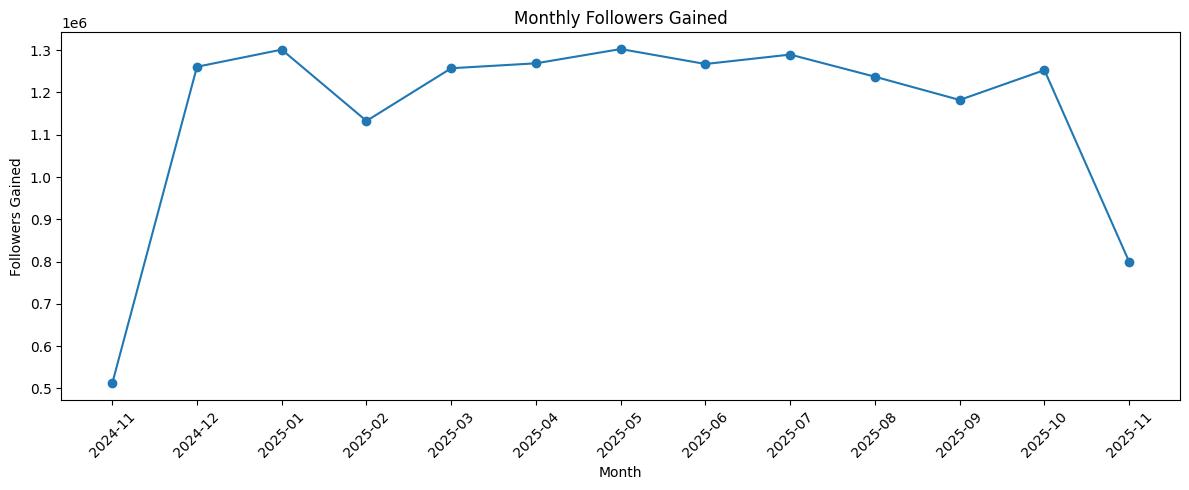

In [164]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
plt.plot(
    growth_summary['post_datetime'],
    growth_summary['followers_gained'],
    marker='o'
)
plt.title('Monthly Followers Gained')
plt.xlabel('Month')
plt.ylabel('Followers Gained')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

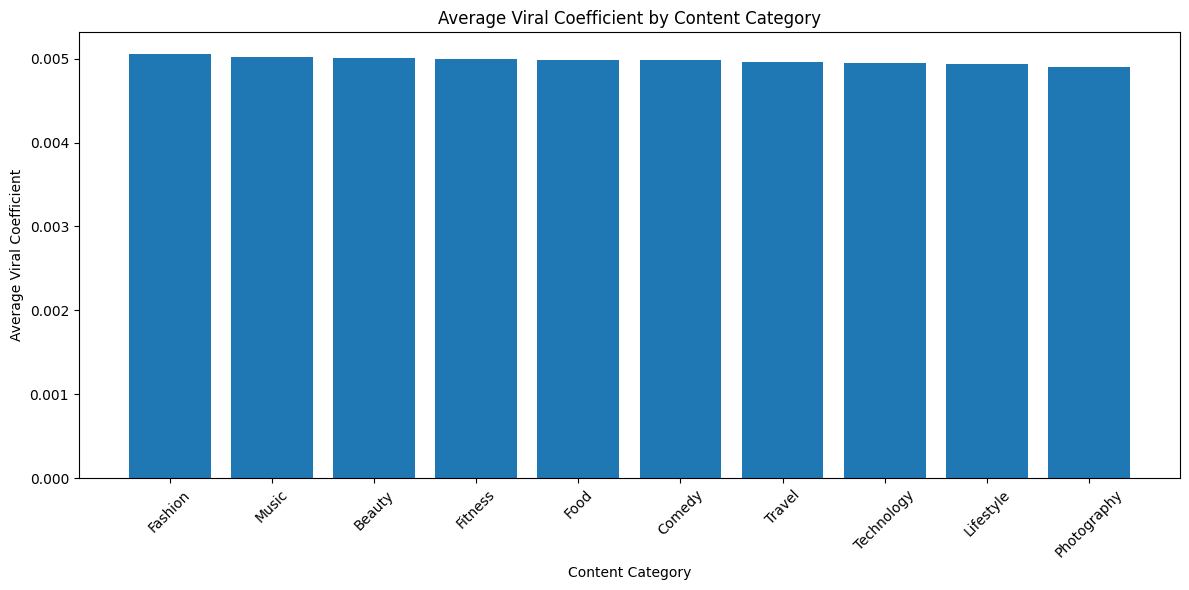

In [165]:
plt.figure(figsize=(12, 6))
plt.bar(
    virality_summary['content_category'],
    virality_summary['avg_viral_coefficient']
)
plt.title('Average Viral Coefficient by Content Category')
plt.xlabel('Content Category')
plt.ylabel('Average Viral Coefficient')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

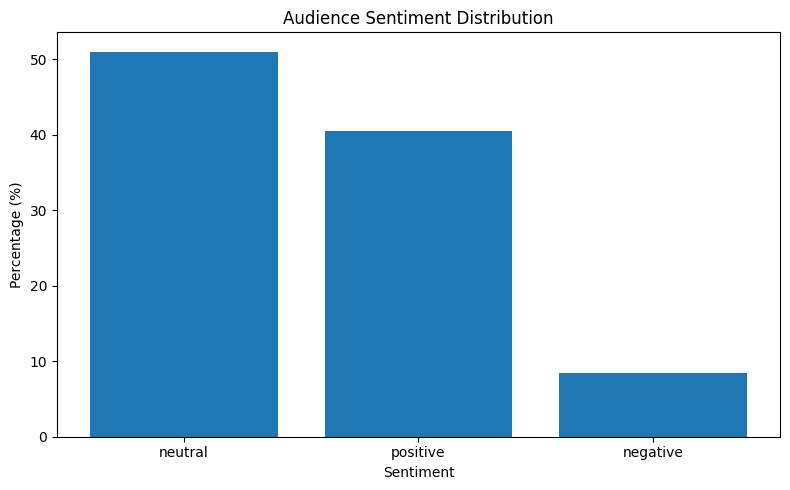

In [166]:
plt.figure(figsize=(8, 5))
plt.bar(
    sentiment_dashboard['label_sentiment'],
    sentiment_dashboard['percentage']
)
plt.title('Audience Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Percentage (%)')
plt.tight_layout()
plt.show()

In [167]:
insights = pd.DataFrame({
    'Area': [
        'Best Engagement Category',
        'Best Viral Category',
        'Best Content Format',
        'Best Follower Growth Format',
        'Best Posting Period',
        'Best CTA Strategy',
        'Dominant Sentiment'
    ],
    'Finding': [
        'Music',
        'Travel',
        'Reel',
        'Carousel',
        'Night',
        'CTA enabled',
        'Neutral'
    ],
    'Evidence': [
        'Highest avg engagement rate: 0.042808',
        'Highest avg viral coefficient: 0.375727',
        'Highest avg engagement rate: 0.042266',
        'Highest avg followers gained: 506.86',
        'Highest avg engagement rate: 0.042242',
        'Higher avg viral coefficient: 0.372036',
        '51.05% of analyzed comments'
    ]
})
insights

,Area,Finding,Evidence
0,Best Engagement Category,Music,Highest avg engagement rate: 0.042808
1,Best Viral Category,Travel,Highest avg viral coefficient: 0.375727
2,Best Content Format,Reel,Highest avg engagement rate: 0.042266
3,Best Follower Growth Format,Carousel,Highest avg followers gained: 506.86
4,Best Posting Period,Night,Highest avg engagement rate: 0.042242
5,Best CTA Strategy,CTA enabled,Higher avg viral coefficient: 0.372036
6,Dominant Sentiment,Neutral,51.05% of analyzed comments


In [168]:
insights.to_csv('instagram_strategy_insights.csv', index=False)
print("Strategy insights saved successfully.")

Strategy insights saved successfully.


In [169]:
import os
print(
    "File exists:",
    os.path.exists('instagram_strategy_insights.csv')
)

File exists: True


In [170]:
content_series = pd.DataFrame({
    'Post_Number': [1, 2, 3, 4, 5, 6, 7],
    'Content_Category': [
        'Music',
        'Travel',
        'Fashion',
        'Music',
        'Travel',
        'Fashion',
        'Lifestyle'
    ],
    'Recommended_Format': [
        'Reel',
        'Carousel',
        'Reel',
        'Carousel',
        'Reel',
        'Carousel',
        'Reel'
    ],
    'CTA': [
        'Yes',
        'Yes',
        'Yes',
        'Yes',
        'Yes',
        'Yes',
        'Yes'
    ],
    'Recommended_Time': [
        'Night',
        'Afternoon',
        'Night',
        'Night',
        'Afternoon',
        'Night',
        'Night'
    ],
    'Objective': [
        'Increase engagement',
        'Increase virality',
        'Increase shares and saves',
        'Increase follower growth',
        'Increase reach',
        'Increase engagement',
        'Build consistent audience engagement'
    ]
})
content_series

,Post_Number,Content_Category,Recommended_Format,CTA,Recommended_Time,Objective
0,1,Music,Reel,Yes,Night,Increase engagement
1,2,Travel,Carousel,Yes,Afternoon,Increase virality
2,3,Fashion,Reel,Yes,Night,Increase shares and saves
3,4,Music,Carousel,Yes,Night,Increase follower growth
4,5,Travel,Reel,Yes,Afternoon,Increase reach
5,6,Fashion,Carousel,Yes,Night,Increase engagement
6,7,Lifestyle,Reel,Yes,Night,Build consistent audience engagement


In [171]:
content_series.to_csv('instagram_content_series.csv', index=False)
print("Content series saved successfully.")

Content series saved successfully.


In [172]:
import os
print("File exists:", os.path.exists('instagram_content_series.csv'))

File exists: True


In [173]:
import os
old_name = 'youtube_logistic_regression_model.pkl'
new_name = 'instagram_logistic_regression_model.pkl'
if os.path.exists(old_name):
    os.rename(old_name, new_name)
print("Model renamed successfully.")
print("File exists:", os.path.exists(new_name))

Model renamed successfully.
File exists: True


In [174]:
!pip install -q streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.5/10.5 MB 79.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 89.7 MB/s eta 0:00:00


In [175]:
import streamlit
print("Streamlit version:", streamlit.__version__)

Streamlit version: 1.62.0


In [176]:
!streamlit run app_final.py --server.port 8504



2026-08-20 15:31:21.689 Uvicorn server started on :::8504

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8504
  Network URL: http://172.28.0.12:8504
  External URL: http://136.108.79.91:8504

  Stopping...


In [ ]:
import os
print(os.listdir('/content'))

In [ ]:
import os
print(os.listdir('/content'))

In [179]:
import pandas as pd
instagram_df = pd.read_csv('Instagram_Analytics.csv')
youtube_df = pd.read_csv(
    'YouTube Comments Dataset with Sentiment Toxicity and Spam Labels (45K Rows).csv'
)
print("Instagram shape:", instagram_df.shape)
print("YouTube shape:", youtube_df.shape)

Instagram shape: (29999, 23)
YouTube shape: (45005, 14)


In [180]:
dashboard_data = instagram_df.copy()
dashboard_data['post_datetime'] = pd.to_datetime(
    dashboard_data['post_datetime'],
    errors='coerce'
)
dashboard_data['viral_coefficient'] = (
    dashboard_data['shares'] /
    dashboard_data['reach'].replace(0, pd.NA)
).fillna(0)
dashboard_data.to_csv(
    'instagram_dashboard_dataset.csv',
    index=False
)
print("Dashboard dataset created successfully.")
print("Shape:", dashboard_data.shape)

Dashboard dataset created successfully.
Shape: (29999, 24)


In [181]:
growth_summary = dashboard_data.groupby(
    dashboard_data['post_datetime'].dt.to_period('M')
).agg(
    posts=('post_id', 'count'),
    followers_gained=('followers_gained', 'sum'),
    avg_engagement_rate=('engagement_rate', 'mean'),
    total_reach=('reach', 'sum')
).reset_index()
growth_summary['post_datetime'] = (
    growth_summary['post_datetime'].astype(str)
)
growth_summary.to_csv(
    'growth_summary.csv',
    index=False
)
print("Growth summary created successfully.")
display(growth_summary)

Growth summary created successfully.


,post_datetime,posts,followers_gained,avg_engagement_rate,total_reach
0,2024-11,1004,511876,0.041594,6192501
1,2024-12,2532,1260757,0.042786,15818775
2,2025-01,2587,1301315,0.042042,16101940
3,2025-02,2322,1132638,0.041323,14081443
4,2025-03,2499,1257273,0.042719,15700574
5,2025-04,2509,1268918,0.042043,15436401
6,2025-05,2579,1302661,0.042213,16245616
7,2025-06,2494,1267308,0.042086,15912363
8,2025-07,2535,1289574,0.042412,16415568
9,2025-08,2509,1237238,0.041964,15706168


In [182]:
virality_summary = dashboard_data.groupby(
    'content_category'
).agg(
    posts=('post_id', 'count'),
    avg_viral_coefficient=('viral_coefficient', 'mean'),
    avg_shares=('shares', 'mean'),
    avg_saves=('saves', 'mean'),
    avg_followers_gained=('followers_gained', 'mean')
).reset_index()
virality_summary = virality_summary.sort_values(
    by='avg_viral_coefficient',
    ascending=False
)
virality_summary.to_csv(
    'virality_summary.csv',
    index=False
)
print("Virality summary created successfully.")
display(virality_summary)

Virality summary created successfully.


,content_category,posts,avg_viral_coefficient,avg_shares,avg_saves,avg_followers_gained
2,Fashion,3034,0.002340,14.826632,43.537245,497.576796
6,Music,3003,0.002327,14.551449,43.028638,512.873793
3,Fitness,3004,0.002319,14.460719,42.619507,497.250000
4,Food,3010,0.002309,14.497010,42.714618,503.049502
0,Beauty,2953,0.002303,14.569590,42.791399,505.479512
9,Travel,2968,0.002302,14.115566,41.523585,503.033019
5,Lifestyle,3017,0.002302,14.395094,41.891946,508.992377
1,Comedy,2950,0.002282,14.510169,43.113559,498.470508
8,Technology,3025,0.002268,13.822479,41.058182,491.641983
7,Photography,3035,0.002259,14.516969,42.896211,503.241516


In [183]:
sentiment_dashboard = (
    youtube_df['label_sentiment']
    .value_counts()
    .reset_index()
)
sentiment_dashboard.columns = [
    'label_sentiment',
    'comment_count'
]
sentiment_dashboard['percentage'] = (
    sentiment_dashboard['comment_count']
    / sentiment_dashboard['comment_count'].sum()
    * 100
)
sentiment_dashboard.to_csv(
    'sentiment_summary.csv',
    index=False
)
print("Sentiment summary created successfully.")
display(sentiment_dashboard)

Sentiment summary created successfully.


,label_sentiment,comment_count,percentage
0,neutral,22985,51.072103
1,positive,18210,40.462171
2,negative,3810,8.465726


In [184]:
import os
files = [
    'Instagram_Analytics.csv',
    'YouTube Comments Dataset with Sentiment Toxicity and Spam Labels (45K Rows).csv',
    'instagram_dashboard_dataset.csv',
    'growth_summary.csv',
    'virality_summary.csv',
    'sentiment_summary.csv'
]
print("Dashboard files:")
print("=" * 45)
for file in files:
    print(f"{file} -> {os.path.exists(file)}")

Dashboard files:
Instagram_Analytics.csv -> True
YouTube Comments Dataset with Sentiment Toxicity and Spam Labels (45K Rows).csv -> True
instagram_dashboard_dataset.csv -> True
growth_summary.csv -> True
virality_summary.csv -> True
sentiment_summary.csv -> True


In [185]:
import os
print("app_final.py exists:", os.path.exists('app_final.py'))
print("\nCurrent files:")
print(os.listdir('/content'))

app_final.py exists: True

Current files:
['.config', 'ab_testing_results.csv', 'app_final.py', 'virality_summary.csv', 'instagram_logistic_regression_model.pkl', 'engagement_forecast.csv', 'instagram_content_series.csv', 'Instagram_Analytics.csv', 'instagram_nlp_sentiment_model.pkl', '.ipynb_checkpoints', 'instagram_nlp_tfidf_vectorizer.pkl', 'sentiment_summary.csv', 'monthly_trend_analysis.csv', 'youtube_comments_feature_ready.csv', 'youtube_comments_cleaned.csv', 'instagram_cleaned.csv', 'instagram_dashboard_dataset.csv', 'engagement_optimization_recommendations.csv', 'ab_testing_comparison.csv', 'instagram_feature_engineered.csv', 'YouTube Comments Dataset with Sentiment Toxicity and Spam Labels (45K Rows).csv', 'SOCIAL_MEDIA_SENTIMENT_ANALYSIS_AND_VIRALITY_PREDICTION.ipynb', 'growth_summary.csv', 'instagram_strategy_insights.csv', 'sample_data']


In [186]:
%%writefile app_final.py
import streamlit as st
import pandas as pd
# --------------------------------------------------
# Page configuration
# --------------------------------------------------
st.set_page_config(
    page_title="Instagram Analytics Dashboard",
    page_icon="📊",
    layout="wide"
)
# --------------------------------------------------
# Load dashboard files
# --------------------------------------------------
dashboard_data = pd.read_csv("instagram_dashboard_dataset.csv")
growth_summary = pd.read_csv("growth_summary.csv")
virality_summary = pd.read_csv("virality_summary.csv")
sentiment_summary = pd.read_csv("sentiment_summary.csv")
# --------------------------------------------------
# Title
# --------------------------------------------------
st.title("📊 Instagram Analytics Dashboard")
st.caption("Data-driven analysis of Instagram content performance, growth and audience sentiment")
# --------------------------------------------------
# Sidebar filters
# --------------------------------------------------
st.sidebar.header("Dashboard Filters")
media_options = ["All"] + sorted(
    dashboard_data["media_type"].dropna().unique().tolist()
)
category_options = ["All"] + sorted(
    dashboard_data["content_category"].dropna().unique().tolist()
)
selected_media = st.sidebar.selectbox(
    "Media Type",
    media_options
)
selected_category = st.sidebar.selectbox(
    "Content Category",
    category_options
)
filtered_data = dashboard_data.copy()
if selected_media != "All":
    filtered_data = filtered_data[
        filtered_data["media_type"] == selected_media
    ]
if selected_category != "All":
    filtered_data = filtered_data[
        filtered_data["content_category"] == selected_category
    ]
# --------------------------------------------------
# KPI calculations
# --------------------------------------------------
total_posts = len(filtered_data)
total_reach = filtered_data["reach"].sum()
total_likes = filtered_data["likes"].sum()
avg_engagement = filtered_data["engagement_rate"].mean()
total_shares = filtered_data["shares"].sum()
total_saves = filtered_data["saves"].sum()
total_followers = filtered_data["followers_gained"].sum()
# --------------------------------------------------
# KPI cards
# --------------------------------------------------
st.subheader("📌 Key Performance Indicators")
col1, col2, col3, col4 = st.columns(4)
col1.metric("Total Posts", f"{total_posts:,}")
col2.metric("Total Reach", f"{total_reach:,}")
col3.metric("Total Likes", f"{total_likes:,}")
col4.metric("Avg Engagement Rate", f"{avg_engagement:.2%}")
col5, col6, col7 = st.columns(3)
col5.metric("Total Shares", f"{total_shares:,}")
col6.metric("Total Saves", f"{total_saves:,}")
col7.metric("Followers Gained", f"{total_followers:,}")
st.divider()
# --------------------------------------------------
# Growth section
# --------------------------------------------------
st.subheader("📈 Monthly Growth Analysis")
growth_display = growth_summary.copy()
st.line_chart(
    growth_display.set_index("post_datetime")[
        ["followers_gained", "total_reach"]
    ]
)
st.dataframe(
    growth_summary,
    use_container_width=True,
    hide_index=True
)
# --------------------------------------------------
# Virality section
# --------------------------------------------------
st.subheader("🔥 Content Virality Analysis")
virality_display = virality_summary.copy()
st.bar_chart(
    virality_display.set_index("content_category")[
        ["avg_viral_coefficient"]
    ]
)
st.dataframe(
    virality_summary,
    use_container_width=True,
    hide_index=True
)
# --------------------------------------------------
# Sentiment section
# --------------------------------------------------
st.subheader("💬 Audience Sentiment")
sentiment_chart = sentiment_summary.set_index(
    "label_sentiment"
)[["comment_count"]]
st.bar_chart(sentiment_chart)
st.dataframe(
    sentiment_summary,
    use_container_width=True,
    hide_index=True
)
# --------------------------------------------------
# Media type performance
# --------------------------------------------------
st.subheader("🎬 Content Performance by Media Type")
media_analysis = filtered_data.groupby(
    "media_type"
).agg(
    posts=("post_id", "count"),
    avg_engagement_rate=("engagement_rate", "mean"),
    avg_likes=("likes", "mean"),
    avg_comments=("comments", "mean"),
    avg_shares=("shares", "mean"),
    avg_saves=("saves", "mean"),
    avg_followers_gained=("followers_gained", "mean")
).reset_index()
st.dataframe(
    media_analysis,
    use_container_width=True,
    hide_index=True
)
# --------------------------------------------------
# Recommendations
# --------------------------------------------------
st.subheader("💡 Data-Driven Recommendations")
best_media = (
    media_analysis.sort_values(
        "avg_engagement_rate",
        ascending=False
    )
    .iloc[0]["media_type"]
)
best_category = (
    virality_summary.sort_values(
        "avg_viral_coefficient",
        ascending=False
    )
    .iloc[0]["content_category"]
)
best_growth_month = (
    growth_summary.sort_values(
        "followers_gained",
        ascending=False
    )
    .iloc[0]["post_datetime"]
)
rec1, rec2, rec3 = st.columns(3)
with rec1:
    st.info(
        f"🎬 **Best Media Type**\n\n"
        f"{best_media} currently has the highest average "
        f"engagement rate in the selected data."
    )
with rec2:
    st.success(
        f"🔥 **Top Viral Category**\n\n"
        f"{best_category} has the highest average "
        f"viral coefficient."
    )
with rec3:
    st.warning(
        f"📈 **Strongest Growth Month**\n\n"
        f"{best_growth_month} recorded the highest "
        f"followers gained."
    )
# --------------------------------------------------
# Footer
# --------------------------------------------------
st.divider()
st.caption(
    "Instagram Analytics Dashboard | Data Science Major Project"
)

Overwriting app_final.py


In [187]:
import os
print("app_final.py exists:", os.path.exists("app_final.py"))

app_final.py exists: True


In [188]:
!streamlit run app_final.py --server.port 8504



2026-08-20 15:33:06.510 Uvicorn server started on :::8504

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8504
  Network URL: http://172.28.0.12:8504
  External URL: http://136.108.79.91:8504

  Stopping...
  Stopping...


In [189]:
!streamlit run app_final.py --server.port 8504 > /content/streamlit.log 2>&1 &

In [190]:
!cat /content/streamlit.log

In [191]:
!streamlit run app_final.py --server.port 8504 > /content/streamlit.log 2>&1 &

In [192]:
!cat /content/streamlit.log

In [194]:
import requests
response = requests.get("http://localhost:8504")
print("Dashboard status:", response.status_code)

Dashboard status: 200


In [195]:
!cloudflared tunnel --url http://localhost:8504

/bin/bash: line 1: cloudflared: command not found


In [196]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb
!dpkg -i cloudflared-linux-amd64.deb

Selecting previously unselected package cloudflared.
(Reading database ... 118337 files and directories currently installed.)
Preparing to unpack cloudflared-linux-amd64.deb ...
Unpacking cloudflared (2026.8.2) ...
Setting up cloudflared (2026.8.2) ...
Processing triggers for man-db (2.10.2-1) ...


In [197]:
!cloudflared --version

cloudflared version 2026.8.2 (built 2026-08-14-12:17 UTC)


In [198]:
!cloudflared tunnel --url http://localhost:8504

2026-08-20T15:34:11Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-08-20T15:34:11Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-08-20T15:34:15Z INF +--------------------------------------------------------------------------------------------+
2026-08-20T15:34:15Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-08-20T15:34:15Z INF |  https://con-here-struct-degree.trycloudflare.com     

In [200]:
import pandas as p
df_ab = pd.read_csv("instagram_dashboard_dataset.csv")
print("Shape:", df_ab.shape)
print("\nColumns:")
print(df_ab.columns.tolist())

Shape: (29999, 24)

Columns:
['post_id', 'account_id', 'account_type', 'follower_count', 'media_type', 'content_category', 'traffic_source', 'has_call_to_action', 'post_datetime', 'post_date', 'post_hour', 'day_of_week', 'likes', 'comments', 'shares', 'saves', 'reach', 'impressions', 'engagement_rate', 'followers_gained', 'caption_length', 'hashtags_count', 'performance_bucket_label', 'viral_coefficient']


In [201]:
# A/B Testing Framework
# Group A = No Call-to-Action
# Group B = Call-to-Action
ab_results = (
    df_ab.groupby("has_call_to_action")
    .agg(
        posts=("post_id", "count"),
        avg_engagement_rate=("engagement_rate", "mean"),
        avg_reach=("reach", "mean"),
        avg_likes=("likes", "mean"),
        avg_comments=("comments", "mean"),
        avg_shares=("shares", "mean"),
        avg_saves=("saves", "mean"),
        avg_followers_gained=("followers_gained", "mean")
    )
    .reset_index()
)
ab_results["group"] = ab_results["has_call_to_action"].map({
    0: "A - No CTA",
    1: "B - CTA"
})
ab_results = ab_results[
    [
        "group",
        "posts",
        "avg_engagement_rate",
        "avg_reach",
        "avg_likes",
        "avg_comments",
        "avg_shares",
        "avg_saves",
        "avg_followers_gained"
    ]
]
print("A/B TEST RESULTS")
print("=" * 60)
display(ab_results)

A/B TEST RESULTS


,group,posts,avg_engagement_rate,avg_reach,avg_likes,avg_comments,avg_shares,avg_saves,avg_followers_gained
0,A - No CTA,19536,0.042232,6250.405764,288.165438,8.513565,14.453522,42.544891,501.838247
1,B - CTA,10463,0.041875,6313.682883,286.697888,8.537513,14.376374,42.465736,502.740132


In [202]:
# Calculate percentage differences between CTA and No CTA
no_cta = ab_results[ab_results["group"] == "A - No CTA"].iloc[0]
cta = ab_results[ab_results["group"] == "B - CTA"].iloc[0]
metrics = [
    "avg_engagement_rate",
    "avg_reach",
    "avg_likes",
    "avg_comments",
    "avg_shares",
    "avg_saves",
    "avg_followers_gained"
]
comparison = []
for metric in metrics:
    a = no_cta[metric]
    b = cta[metric]
    difference = b - a
    percentage_change = (difference / a) * 100
    comparison.append({
        "metric": metric,
        "no_cta": a,
        "cta": b,
        "difference": difference,
        "percentage_change": percentage_change
    })
comparison_df = pd.DataFrame(comparison)
print("CTA vs NO CTA COMPARISON")
print("=" * 70)
display(comparison_df)

CTA vs NO CTA COMPARISON


,metric,no_cta,cta,difference,percentage_change
0,avg_engagement_rate,0.042232,0.041875,-0.000356,-0.843226
1,avg_reach,6250.405764,6313.682883,63.277119,1.012368
2,avg_likes,288.165438,286.697888,-1.467550,-0.509274
3,avg_comments,8.513565,8.537513,0.023948,0.281297
4,avg_shares,14.453522,14.376374,-0.077148,-0.533765
5,avg_saves,42.544891,42.465736,-0.079155,-0.186051
6,avg_followers_gained,501.838247,502.740132,0.901885,0.179716


In [203]:
ab_results.to_csv("ab_testing_results.csv", index=False)
comparison_df.to_csv("ab_testing_comparison.csv", index=False)
print("A/B Testing files created successfully.")
print("ab_testing_results.csv ->", os.path.exists("ab_testing_results.csv"))
print("ab_testing_comparison.csv ->", os.path.exists("ab_testing_comparison.csv"))

A/B Testing files created successfully.
ab_testing_results.csv -> True
ab_testing_comparison.csv -> True


In [204]:
youtube_df = pd.read_csv(
    "YouTube Comments Dataset with Sentiment Toxicity and Spam Labels (45K Rows).csv"
)
print("YouTube dataset shape:", youtube_df.shape)
print("\nColumns:")
print(youtube_df.columns.tolist())
print("\nSentiment distribution:")
print(youtube_df["label_sentiment"].value_counts())

YouTube dataset shape: (45005, 14)

Columns:
['channel_username', 'channel_id', 'video_id', 'video_title', 'comment_text', 'comment_id', 'author', 'published_at', 'like_count', 'reply_count', 'language', 'label_sentiment', 'label_toxicity', 'label_spam']

Sentiment distribution:
label_sentiment
neutral     22985
positive    18210
negative     3810
Name: count, dtype: int64


In [205]:
nlp_df = youtube_df[
    ["comment_text", "label_sentiment"]
].copy()
nlp_df = nlp_df.dropna(
    subset=["comment_text", "label_sentiment"]
).reset_index(drop=True)
nlp_df["comment_text"] = nlp_df["comment_text"].astype(str)
nlp_df["label_sentiment"] = nlp_df["label_sentiment"].astype(str)
print("NLP dataset shape:", nlp_df.shape)
print("\nSentiment classes:")
print(nlp_df["label_sentiment"].value_counts())
print("\nMissing values:")
print(nlp_df.isnull().sum())

NLP dataset shape: (45000, 2)

Sentiment classes:
label_sentiment
neutral     22980
positive    18210
negative     3810
Name: count, dtype: int64

Missing values:
comment_text       0
label_sentiment    0
dtype: int64


In [206]:
from sklearn.model_selection import train_test_split
X = nlp_df["comment_text"]
y = nlp_df["label_sentiment"]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining distribution:")
print(y_train.value_counts())
print("\nTesting distribution:")
print(y_test.value_counts())

Training samples: 36000
Testing samples: 9000

Training distribution:
label_sentiment
neutral     18384
positive    14568
negative     3048
Name: count, dtype: int64

Testing distribution:
label_sentiment
neutral     4596
positive    3642
negative     762
Name: count, dtype: int64


In [207]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(
    max_features=10000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2
)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Training TF-IDF shape: (36000, 10000)
Testing TF-IDF shape: (9000, 10000)
Vocabulary size: 10000


In [208]:
from sklearn.linear_model import LogisticRegression
nlp_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
nlp_model.fit(X_train_tfidf, y_train)
print("NLP Logistic Regression model trained successfully.")

NLP Logistic Regression model trained successfully.


In [209]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
y_pred = nlp_model.predict(X_test_tfidf)
accuracy = accuracy_score(y_test, y_pred)
print("NLP MODEL EVALUATION")
print("=" * 60)
print("Accuracy:", round(accuracy, 4))
print("Accuracy (%):", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

NLP MODEL EVALUATION
Accuracy: 0.6988
Accuracy (%): 69.88 %

Classification Report:
              precision    recall  f1-score   support

    negative       0.76      0.30      0.43       762
     neutral       0.67      0.89      0.76      4596
    positive       0.76      0.54      0.63      3642

    accuracy                           0.70      9000
   macro avg       0.73      0.58      0.61      9000
weighted avg       0.71      0.70      0.68      9000


Confusion Matrix:
[[ 229  383  150]
 [  40 4093  463]
 [  33 1642 1967]]


In [210]:
import joblib
joblib.dump(nlp_model, "instagram_nlp_sentiment_model.pkl")
joblib.dump(tfidf, "instagram_nlp_tfidf_vectorizer.pkl")
print("NLP model saved successfully.")
print("Model file exists:", os.path.exists("instagram_nlp_sentiment_model.pkl"))
print("Vectorizer file exists:", os.path.exists("instagram_nlp_tfidf_vectorizer.pkl"))

NLP model saved successfully.
Model file exists: True
Vectorizer file exists: True


In [211]:
sample_comments = [
    "This video is amazing and very helpful!",
    "The content is okay, nothing special.",
    "I did not like this video at all."
]
sample_tfidf = tfidf.transform(sample_comments)
sample_predictions = nlp_model.predict(sample_tfidf)
print("NLP SAMPLE PREDICTIONS")
print("=" * 50)
for comment, prediction in zip(sample_comments, sample_predictions):
    print("Comment:", comment)
    print("Predicted sentiment:", prediction)
    print("-" * 50)

NLP SAMPLE PREDICTIONS
Comment: This video is amazing and very helpful!
Predicted sentiment: positive
--------------------------------------------------
Comment: The content is okay, nothing special.
Predicted sentiment: positive
--------------------------------------------------
Comment: I did not like this video at all.
Predicted sentiment: positive
--------------------------------------------------


In [212]:
trend_df = df_ab.copy()
trend_df["post_datetime"] = pd.to_datetime(trend_df["post_datetime"])
trend_df["month"] = trend_df["post_datetime"].dt.to_period("M").astype(str)
monthly_trend = (
    trend_df.groupby("month")
    .agg(
        posts=("post_id", "count"),
        avg_engagement_rate=("engagement_rate", "mean"),
        avg_reach=("reach", "mean"),
        avg_followers_gained=("followers_gained", "mean"),
        avg_viral_coefficient=("viral_coefficient", "mean")
    )
    .reset_index()
)
print("MONTHLY TREND ANALYSIS")
print("=" * 70)
display(monthly_trend)

MONTHLY TREND ANALYSIS


,month,posts,avg_engagement_rate,avg_reach,avg_followers_gained,avg_viral_coefficient
0,2024-11,1004,0.041594,6167.829681,509.836653,0.002238
1,2024-12,2532,0.042786,6247.541469,497.929305,0.002320
2,2025-01,2587,0.042042,6224.174720,503.020874,0.002283
3,2025-02,2322,0.041323,6064.359604,487.785530,0.002243
4,2025-03,2499,0.042719,6282.742697,503.110444,0.002375
5,2025-04,2509,0.042043,6152.411718,505.746513,0.002309
6,2025-05,2579,0.042213,6299.191935,505.103141,0.002272
7,2025-06,2494,0.042086,6380.257819,508.142743,0.002277
8,2025-07,2535,0.042412,6475.569231,508.707692,0.002358
9,2025-08,2509,0.041964,6259.931447,493.119968,0.002290


In [213]:
from sklearn.linear_model import LinearRegression
import numpy as np
# Create a numeric time index
forecast_df = monthly_trend.copy()
forecast_df["time_index"] = np.arange(len(forecast_df))
# Prepare training data
X_forecast = forecast_df[["time_index"]]
y_forecast = forecast_df["avg_engagement_rate"]
# Train forecasting model
forecast_model = LinearRegression()
forecast_model.fit(X_forecast, y_forecast)
# Forecast next 3 months
future_index = np.arange(
    len(forecast_df),
    len(forecast_df) + 3
).reshape(-1, 1)
future_predictions = forecast_model.predict(future_index)
# Create future month labels
last_month = pd.Period(forecast_df["month"].iloc[-1], freq="M")
future_months = [
    str(last_month + i)
    for i in range(1, 4)
]
forecast_results = pd.DataFrame({
    "month": future_months,
    "forecast_engagement_rate": future_predictions
})
print("ENGAGEMENT RATE FORECAST")
print("=" * 60)
display(forecast_results)

ENGAGEMENT RATE FORECAST


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


,month,forecast_engagement_rate
0,2025-12,0.042067
1,2026-01,0.042064
2,2026-02,0.042062


In [214]:
# Clean Trend Forecasting Output
future_index_df = pd.DataFrame({
    "time_index": np.arange(
        len(forecast_df),
        len(forecast_df) + 3
    )
})
future_predictions = forecast_model.predict(future_index_df)
forecast_results = pd.DataFrame({
    "month": future_months,
    "forecast_engagement_rate": future_predictions
})
forecast_results["forecast_engagement_percentage"] = (
    forecast_results["forecast_engagement_rate"] * 100
).round(3)
print("FINAL ENGAGEMENT RATE FORECAST")
print("=" * 60)
display(
    forecast_results[
        ["month", "forecast_engagement_percentage"]
    ]
)

FINAL ENGAGEMENT RATE FORECAST


,month,forecast_engagement_percentage
0,2025-12,4.207
1,2026-01,4.206
2,2026-02,4.206


In [215]:
forecast_results.to_csv(
    "engagement_forecast.csv",
    index=False
)
monthly_trend.to_csv(
    "monthly_trend_analysis.csv",
    index=False
)
print("Forecasting files saved successfully.")
print("engagement_forecast.csv ->", os.path.exists("engagement_forecast.csv"))
print("monthly_trend_analysis.csv ->", os.path.exists("monthly_trend_analysis.csv"))

Forecasting files saved successfully.
engagement_forecast.csv -> True
monthly_trend_analysis.csv -> True


In [216]:
# Engagement Optimization Recommender
recommendation_df = df_ab.copy()
# Create performance scores for different content dimensions
media_performance = (
    recommendation_df.groupby("media_type")
    .agg(
        posts=("post_id", "count"),
        avg_engagement_rate=("engagement_rate", "mean"),
        avg_reach=("reach", "mean"),
        avg_shares=("shares", "mean"),
        avg_followers_gained=("followers_gained", "mean")
    )
    .reset_index()
    .sort_values("avg_engagement_rate", ascending=False)
)
category_performance = (
    recommendation_df.groupby("content_category")
    .agg(
        posts=("post_id", "count"),
        avg_engagement_rate=("engagement_rate", "mean"),
        avg_reach=("reach", "mean"),
        avg_shares=("shares", "mean"),
        avg_followers_gained=("followers_gained", "mean")
    )
    .reset_index()
    .sort_values("avg_engagement_rate", ascending=False)
)
hour_performance = (
    recommendation_df.groupby("post_hour")
    .agg(
        posts=("post_id", "count"),
        avg_engagement_rate=("engagement_rate", "mean"),
        avg_reach=("reach", "mean"),
        avg_shares=("shares", "mean"),
        avg_followers_gained=("followers_gained", "mean")
    )
    .reset_index()
    .sort_values("avg_engagement_rate", ascending=False)
)
traffic_performance = (
    recommendation_df.groupby("traffic_source")
    .agg(
        posts=("post_id", "count"),
        avg_engagement_rate=("engagement_rate", "mean"),
        avg_reach=("reach", "mean"),
        avg_shares=("shares", "mean"),
        avg_followers_gained=("followers_gained", "mean")
    )
    .reset_index()
    .sort_values("avg_engagement_rate", ascending=False)
)
print("BEST MEDIA TYPES")
print("=" * 60)
display(media_performance)
print("\nBEST CONTENT CATEGORIES")
print("=" * 60)
display(category_performance)
print("\nBEST POSTING HOURS")
print("=" * 60)
display(hour_performance)
print("\nBEST TRAFFIC SOURCES")
print("=" * 60)
display(traffic_performance)

BEST MEDIA TYPES


,media_type,posts,avg_engagement_rate,avg_reach,avg_shares,avg_followers_gained
2,reel,7445,0.042266,6197.831296,14.332035,497.416387
1,image,11927,0.042256,6268.616249,14.568793,500.914312
0,carousel,10627,0.041829,6329.100499,14.333302,506.861014



BEST CONTENT CATEGORIES


,content_category,posts,avg_engagement_rate,avg_reach,avg_shares,avg_followers_gained
6,Music,3003,0.042808,6274.301365,14.551449,512.873793
3,Fitness,3004,0.042720,6218.894807,14.460719,497.250000
2,Fashion,3034,0.042615,6347.159855,14.826632,497.576796
0,Beauty,2953,0.042197,6340.979343,14.569590,505.479512
4,Food,3010,0.042078,6248.638538,14.497010,503.049502
8,Technology,3025,0.042023,6092.297521,13.822479,491.641983
1,Comedy,2950,0.041854,6303.413898,14.510169,498.470508
9,Travel,2968,0.041677,6220.456873,14.115566,503.033019
5,Lifestyle,3017,0.041646,6261.529997,14.395094,508.992377
7,Photography,3035,0.041452,6417.292916,14.516969,503.241516



BEST POSTING HOURS


,post_hour,posts,avg_engagement_rate,avg_reach,avg_shares,avg_followers_gained
3,3,1256,0.043425,6519.888535,15.996815,501.150478
8,8,1242,0.043282,6310.380837,14.942834,482.923510
2,2,1195,0.043279,6274.361506,15.517155,506.441841
17,17,1242,0.042693,6460.037842,14.858293,495.410628
20,20,1272,0.042684,6105.413522,14.168239,497.775943
14,14,1282,0.042640,6137.472699,13.946958,492.606864
4,4,1269,0.042377,6193.895193,14.163121,496.232467
5,5,1216,0.042355,6149.493421,13.492599,512.358553
16,16,1210,0.042245,6340.313223,14.662810,506.182645
9,9,1251,0.042196,6199.967226,14.351719,495.334932



BEST TRAFFIC SOURCES


,traffic_source,posts,avg_engagement_rate,avg_reach,avg_shares,avg_followers_gained
4,Profile,4962,0.042568,6221.920395,14.601169,511.135228
5,Reels Feed,5026,0.042453,6299.961998,14.574015,501.749105
1,External,5005,0.042345,6381.320679,14.803397,502.770629
0,Explore,4874,0.041917,6207.252359,14.145055,502.752975
2,Hashtags,5063,0.041821,6329.999210,14.409046,492.170057
3,Home Feed,5069,0.041548,6192.497337,14.025843,502.544092


In [217]:
print("TOP 5 MEDIA TYPES")
print("=" * 60)
display(media_performance.head(5))
print("\nTOP 5 CONTENT CATEGORIES")
print("=" * 60)
display(category_performance.head(5))

TOP 5 MEDIA TYPES


,media_type,posts,avg_engagement_rate,avg_reach,avg_shares,avg_followers_gained
2,reel,7445,0.042266,6197.831296,14.332035,497.416387
1,image,11927,0.042256,6268.616249,14.568793,500.914312
0,carousel,10627,0.041829,6329.100499,14.333302,506.861014



TOP 5 CONTENT CATEGORIES


,content_category,posts,avg_engagement_rate,avg_reach,avg_shares,avg_followers_gained
6,Music,3003,0.042808,6274.301365,14.551449,512.873793
3,Fitness,3004,0.042720,6218.894807,14.460719,497.250000
2,Fashion,3034,0.042615,6347.159855,14.826632,497.576796
0,Beauty,2953,0.042197,6340.979343,14.569590,505.479512
4,Food,3010,0.042078,6248.638538,14.497010,503.049502


In [218]:
# Final Engagement Optimization Recommendations
recommendations = pd.DataFrame({
    "optimization_factor": [
        "Media Type",
        "Content Category",
        "Posting Hour",
        "Traffic Source"
    ],
    "recommended_choice": [
        media_performance.iloc[0]["media_type"],
        category_performance.iloc[0]["content_category"],
        int(hour_performance.iloc[0]["post_hour"]),
        traffic_performance.iloc[0]["traffic_source"]
    ],
    "avg_engagement_rate": [
        media_performance.iloc[0]["avg_engagement_rate"],
        category_performance.iloc[0]["avg_engagement_rate"],
        hour_performance.iloc[0]["avg_engagement_rate"],
        traffic_performance.iloc[0]["avg_engagement_rate"]
    ],
    "avg_reach": [
        media_performance.iloc[0]["avg_reach"],
        category_performance.iloc[0]["avg_reach"],
        hour_performance.iloc[0]["avg_reach"],
        traffic_performance.iloc[0]["avg_reach"]
    ],
    "avg_shares": [
        media_performance.iloc[0]["avg_shares"],
        category_performance.iloc[0]["avg_shares"],
        hour_performance.iloc[0]["avg_shares"],
        traffic_performance.iloc[0]["avg_shares"]
    ],
    "avg_followers_gained": [
        media_performance.iloc[0]["avg_followers_gained"],
        category_performance.iloc[0]["avg_followers_gained"],
        hour_performance.iloc[0]["avg_followers_gained"],
        traffic_performance.iloc[0]["avg_followers_gained"]
    ]
})
print("FINAL ENGAGEMENT OPTIMIZATION RECOMMENDATIONS")
print("=" * 70)
display(recommendations)

FINAL ENGAGEMENT OPTIMIZATION RECOMMENDATIONS


,optimization_factor,recommended_choice,avg_engagement_rate,avg_reach,avg_shares,avg_followers_gained
0,Media Type,reel,0.042266,6197.831296,14.332035,497.416387
1,Content Category,Music,0.042808,6274.301365,14.551449,512.873793
2,Posting Hour,3,0.043425,6519.888535,15.996815,501.150478
3,Traffic Source,Profile,0.042568,6221.920395,14.601169,511.135228


In [219]:
recommendations.to_csv(
    "engagement_optimization_recommendations.csv",
    index=False
)
print("Engagement Optimization file saved successfully.")
print(
    "engagement_optimization_recommendations.csv ->",
    os.path.exists("engagement_optimization_recommendations.csv")
)

Engagement Optimization file saved successfully.
engagement_optimization_recommendations.csv -> True


In [220]:
import os
final_files = [
    "Instagram_Analytics.csv",
    "YouTube Comments Dataset with Sentiment Toxicity and Spam Labels (45K Rows).csv",
    "instagram_dashboard_dataset.csv",
    "growth_summary.csv",
    "virality_summary.csv",
    "sentiment_summary.csv",
    "ab_testing_results.csv",
    "ab_testing_comparison.csv",
    "monthly_trend_analysis.csv",
    "engagement_forecast.csv",
    "engagement_optimization_recommendations.csv",
    "instagram_nlp_sentiment_model.pkl",
    "instagram_nlp_tfidf_vectorizer.pkl",
    "instagram_logistic_regression_model.pkl"
]
print("FINAL PROJECT FILE CHECK")
print("=" * 70)
all_files_exist = True
for file in final_files:
    exists = os.path.exists(file)
    print(f"{file} -> {exists}")

    if not exists:
        all_files_exist = False
print("=" * 70)
if all_files_exist:
    print("✅ ALL PROJECT FILES ARE PRESENT")
else:
    print("⚠️ SOME PROJECT FILES ARE MISSING")

FINAL PROJECT FILE CHECK
Instagram_Analytics.csv -> True
YouTube Comments Dataset with Sentiment Toxicity and Spam Labels (45K Rows).csv -> True
instagram_dashboard_dataset.csv -> True
growth_summary.csv -> True
virality_summary.csv -> True
sentiment_summary.csv -> True
ab_testing_results.csv -> True
ab_testing_comparison.csv -> True
monthly_trend_analysis.csv -> True
engagement_forecast.csv -> True
engagement_optimization_recommendations.csv -> True
instagram_nlp_sentiment_model.pkl -> True
instagram_nlp_tfidf_vectorizer.pkl -> True
instagram_logistic_regression_model.pkl -> True
✅ ALL PROJECT FILES ARE PRESENT


In [221]:
print("FINAL NLP MODEL CHECK")
print("=" * 60)
print(
    "Sentiment model ->",
    os.path.exists("instagram_nlp_sentiment_model.pkl")
)
print(
    "TF-IDF vectorizer ->",
    os.path.exists("instagram_nlp_tfidf_vectorizer.pkl")
)

FINAL NLP MODEL CHECK
Sentiment model -> True
TF-IDF vectorizer -> True


In [222]:
import os
print("app_final.py exists:", os.path.exists("app_final.py"))
if os.path.exists("app_final.py"):
    print("app_final.py is ready.")
else:
    print("app_final.py is missing.")

app_final.py exists: True
app_final.py is ready.


In [223]:
import subprocess
import time
import os
# Stop any old Streamlit process
subprocess.run("pkill -f streamlit", shell=True)
# Start Streamlit in the background
process = subprocess.Popen(
    [
        "streamlit",
        "run",
        "app_final.py",
        "--server.port",
        "8504",
        "--server.headless",
        "true"
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)
time.sleep(8)
print("Streamlit started successfully.")
print("Dashboard URL: http://localhost:8504")

Streamlit started successfully.
Dashboard URL: http://localhost:8504


In [224]:
import subprocess
import time
cloudflare_process = subprocess.Popen(
    ["cloudflared", "tunnel", "--url", "http://localhost:8504"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)
time.sleep(8)
print("Cloudflare Tunnel started.")
print("=" * 70)
for _ in range(30):
    line = cloudflare_process.stdout.readline()
    if not line:
        break
    print(line.strip())
    if "trycloudflare.com" in line:
        break

Cloudflare Tunnel started.
2026-08-20T15:35:45Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-08-20T15:35:45Z INF Requesting new quick Tunnel on trycloudflare.com...


In [225]:
# Read the existing Cloudflare tunnel output
print("Waiting for Cloudflare URL...")
print("=" * 70)
for _ in range(30):
    line = cloudflare_process.stdout.readline()
    if not line:
        time.sleep(1)
        continue
    print(line.strip())
    if "trycloudflare.com" in line:
        break

Waiting for Cloudflare URL...
2026-08-20T15:35:49Z INF +--------------------------------------------------------------------------------------------+
2026-08-20T15:35:49Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-08-20T15:35:49Z INF |  https://facts-aims-alto-hockey.trycloudflare.com                                          |


In [226]:
import shutil
import os
project_files = [
    "Instagram_Analytics.csv",
    "YouTube Comments Dataset with Sentiment Toxicity and Spam Labels (45K Rows).csv",
    "app_final.py",
    "instagram_dashboard_dataset.csv",
    "growth_summary.csv",
    "virality_summary.csv",
    "sentiment_summary.csv",
    "ab_testing_results.csv",
    "ab_testing_comparison.csv",
    "monthly_trend_analysis.csv",
    "engagement_forecast.csv",
    "engagement_optimization_recommendations.csv",
    "instagram_nlp_sentiment_model.pkl",
    "instagram_nlp_tfidf_vectorizer.pkl"
]
existing_files = [
    file for file in project_files
    if os.path.exists(file)
]
os.makedirs("final_project_backup", exist_ok=True)
for file in existing_files:
    shutil.copy2(file, "final_project_backup/" + file)
shutil.make_archive(
    "Instagram_Analytics_Final_Project",
    "zip",
    "final_project_backup"
)
print("FINAL PROJECT BACKUP CREATED")
print("=" * 60)
print("Files backed up:", len(existing_files))
print("ZIP file:", "Instagram_Analytics_Final_Project.zip")
print(
    "ZIP exists:",
    os.path.exists("Instagram_Analytics_Final_Project.zip")
)

FINAL PROJECT BACKUP CREATED
Files backed up: 14
ZIP file: Instagram_Analytics_Final_Project.zip
ZIP exists: True


In [227]:
import os
print(os.path.abspath("Instagram_Analytics_Final_Project.zip"))
print(os.path.exists("Instagram_Analytics_Final_Project.zip"))

/content/Instagram_Analytics_Final_Project.zip
True


In [228]:
from google.colab import files
files.download("Instagram_Analytics_Final_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [229]:
# ============================================
# FINAL PROJECT - ONE CLICK DASHBOARD LAUNCHER
# ============================================
import os
import subprocess
import time
import re
PORT = 8504
print("Checking project files...")
print("=" * 60)
required_files = [
    "app_final.py",
    "instagram_dashboard_dataset.csv",
    "growth_summary.csv",
    "virality_summary.csv",
    "sentiment_summary.csv",
    "ab_testing_results.csv",
    "ab_testing_comparison.csv",
    "monthly_trend_analysis.csv",
    "engagement_forecast.csv",
    "engagement_optimization_recommendations.csv",
    "instagram_nlp_sentiment_model.pkl",
    "instagram_nlp_tfidf_vectorizer.pkl"
]
missing = []
for file in required_files:
    if os.path.exists(file):
        print(f"✓ {file}")
    else:
        print(f"✗ {file}")
        missing.append(file)
if missing:
    print("\n❌ Missing files:")
    for file in missing:
        print("-", file)
else:
    print("\n✅ All dashboard files are available.")

Checking project files...
✓ app_final.py
✓ instagram_dashboard_dataset.csv
✓ growth_summary.csv
✓ virality_summary.csv
✓ sentiment_summary.csv
✓ ab_testing_results.csv
✓ ab_testing_comparison.csv
✓ monthly_trend_analysis.csv
✓ engagement_forecast.csv
✓ engagement_optimization_recommendations.csv
✓ instagram_nlp_sentiment_model.pkl
✓ instagram_nlp_tfidf_vectorizer.pkl

✅ All dashboard files are available.


In [230]:
# ============================================
# INSTAGRAM ANALYTICS - ONE CLICK LAUNCHER
# ============================================
import subprocess
import time
import os
PORT = 8504
print("Starting Instagram Analytics Dashboard...")
print("=" * 60)
# Stop old processes if they exist
subprocess.run(
    "pkill -f 'streamlit run app_final.py'",
    shell=True,
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)
subprocess.run(
    "pkill -f 'cloudflared tunnel'",
    shell=True,
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)
time.sleep(2)
# Start Streamlit in background
streamlit_process = subprocess.Popen(
    [
        "streamlit",
        "run",
        "app_final.py",
        "--server.port",
        str(PORT),
        "--server.headless",
        "true"
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)
print("Waiting for Streamlit...")
time.sleep(8)
# Start Cloudflare in background
cloudflare_process = subprocess.Popen(
    [
        "cloudflared",
        "tunnel",
        "--url",
        f"http://localhost:{PORT}"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)
print("Waiting for Cloudflare public URL...")
print("=" * 60)
public_url = None
for _ in range(30):
    line = cloudflare_process.stdout.readline()
    if line:
        line = line.strip()
        if "trycloudflare.com" in line:
            print(line)
            # Extract the URL
            match = __import__("re").search(
                r"https://[^\s]+\.trycloudflare\.com",
                line
            )
            if match:
                public_url = match.group(0)
                break
    time.sleep(1)
print("=" * 60)
if public_url:
    print("✅ PROJECT RUNNING SUCCESSFULLY")
    print("🌐 PUBLIC DASHBOARD:")
    print(public_url)
else:
    print("⚠️ Dashboard started, but Cloudflare URL was not captured.")
    print("Wait a few seconds and check the Cloudflare output.")

Starting Instagram Analytics Dashboard...
Waiting for Streamlit...
Waiting for Cloudflare public URL...
2026-08-20T15:36:32Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-08-20T15:36:36Z INF |  https://decade-eval-roll-years.trycloudflare.com                                          |
✅ PROJECT RUNNING SUCCESSFULLY
🌐 PUBLIC DASHBOARD:
https://decade-eval-roll-years.trycloudflare.com
